In [1]:
import xarray as xr
import numpy as np
import xarray as xr
import numpy as np
import pandas as pd
from scipy.ndimage import label, convolve
from scipy.ndimage import binary_closing
from scipy.ndimage import convolve, label, binary_closing


In [2]:


# ============================================================
# 1. SETTINGS
# ============================================================

FILE_PATH = "/jetfs/scratch/vdeshmukh/2m_data_temp/ERA5_t2m_1979_2025_0p5_land_MJJA.nc"
VAR_NAME = "2t"   # change to "t2m" if needed

# Greece-centered region
LAT_RANGE = slice(34.0, 42.5)
LON_RANGE = slice(19.0, 27.0)
#LAT_RANGE = slice(15.0, 45)
#LON_RANGE = slice(10, 60)



OUT_MASK_FILE = "heatwave_mask_greece.nc"
OUT_EVENTS_FILE = "heatwave_events_greece.csv"

# optional: save anomaly too
OUT_ANOM_FILE = "t_anom_greece.nc"

# Climatology
CLIM_START = "1992-06-01"
CLIM_END   = "2025-08-31"

# Heatwave detection settings
SUMMER_MONTHS = [6, 7, 8]
PERCENTILE = 0.95
WINDOW_DAYS = 8
L_DEG = 1.5
ALPHA = 0.70
MIN_DURATION = 5
OVERLAP_THRESHOLD = 0.60

# ============================================================
# 2. OPEN DATA
# ============================================================

print("Opening dataset...", flush=True)
ds = xr.open_dataset(FILE_PATH)
ds = ds.assign_coords(
    lon=((ds.lon + 180) % 360) - 180
).sortby("lon")

ds = ds.sel(lat=LAT_RANGE, lon=LON_RANGE)

if VAR_NAME not in ds:
    raise KeyError(f"Variable '{VAR_NAME}' not found. Available variables: {list(ds.data_vars)}")

t = ds[VAR_NAME]

print("Attributes:", t.attrs)

raw_min = float(t.min())
raw_max = float(t.max())
print(f"Raw min/max: {raw_min:.3f}, {raw_max:.3f}")

# Convert Kelvin to Celsius if needed
if raw_max > 200:
    t = t - 273.15
    print("Converted from Kelvin to Celsius.", flush=True)

print(f"Post-conversion min/max: {float(t.min()):.3f}, {float(t.max()):.3f}")

# Land mask from first timestep
land_mask = t.isel(time=0).notnull()

# Remove Feb 29 for 365-day climatology
is_feb29 = (t.time.dt.month == 2) & (t.time.dt.day == 29)
t = t.sel(time=~is_feb29)

# ============================================================
# 3. DAILY MAXIMUM TEMPERATURE
# ============================================================

print("Computing daily Tmax...", flush=True)
t_daily = t.resample(time="1D").max()

is_feb29_daily = (t_daily.time.dt.month == 2) & (t_daily.time.dt.day == 29)
t_daily = t_daily.sel(time=~is_feb29_daily)

print(f"Daily Tmax min/max: {float(t_daily.min()):.3f}, {float(t_daily.max()):.3f}")

# ============================================================
# 4. DAILY CLIMATOLOGICAL THRESHOLD
# ============================================================

print("Building climatological threshold...", flush=True)
t_clim = t_daily.sel(time=slice(CLIM_START, CLIM_END))

if t_clim.time.size == 0:
    raise ValueError("No data found in the selected climatology period.")

clim_doy = t_clim.time.dt.dayofyear.values

def circular_day_distance(a, b):
    d = np.abs(a - b)
    return np.minimum(d, 365 - d)

threshold_list = []

for target_doy in range(1, 366):
    keep = circular_day_distance(clim_doy, target_doy) <= WINDOW_DAYS
    thresh = np.nanpercentile(t_clim.values[keep, :, :], 100 * PERCENTILE, axis=0)
    threshold_list.append(thresh)

threshold = xr.DataArray(
    np.stack(threshold_list, axis=0),
    coords={
        "dayofyear": np.arange(1, 366),
        "lat": t_daily.lat,
        "lon": t_daily.lon
    },
    dims=("dayofyear", "lat", "lon"),
    name="threshold"
) 

print("Threshold computed.", flush=True)

# ============================================================
# 5. JJA HOT-DAY MASK + DAILY ANOMALY
# ============================================================

print("Selecting JJA and computing exceedance mask...", flush=True)

t_jja = t_daily.where(t_daily.time.dt.month.isin(SUMMER_MONTHS), drop=True)
jja_doy = t_jja.time.dt.dayofyear

threshold_for_jja = threshold.sel(dayofyear=xr.DataArray(jja_doy.values, dims="time"))

# --- THIS IS THE VARIABLE YOU WANTED ---
t_anom = t_jja - threshold_for_jja
t_anom.name = "t_anom"
t_anom.attrs["description"] = "Daily Tmax anomaly relative to moving climatological percentile threshold"
t_anom.attrs["units"] = "degC"

# optional save
#print(f"Saved: {OUT_ANOM_FILE}", flush=True)

hot = (t_jja > threshold_for_jja) & land_mask
hot.name = "hot_exceedance"

# ============================================================
# 6. SPATIAL COHERENCE FILTER
# ============================================================

print("Applying spatial coherence filter...", flush=True)

dlat = float(abs(t_jja.lat[1] - t_jja.lat[0]))
dlon = float(abs(t_jja.lon[1] - t_jja.lon[0]))

nlat_win = max(1, int(round(L_DEG / dlat)))
nlon_win = max(1, int(round(L_DEG / dlon)))

if nlat_win % 2 == 0:
    nlat_win += 1
if nlon_win % 2 == 0:
    nlon_win += 1

kernel = np.ones((nlat_win, nlon_win), dtype=float)

lat_weights_1d = np.cos(np.deg2rad(t_jja.lat.values))
lat_weights_2d = lat_weights_1d[:, None] * np.ones((len(t_jja.lat), len(t_jja.lon)))

hot_np = hot.values.astype(float)
land_np = land_mask.values.astype(float)

coherent_np = np.zeros_like(hot_np, dtype=bool)

for tt in range(hot_np.shape[0]):
    if tt % 20 == 0:
        print(f"Spatial filter day {tt+1}/{hot_np.shape[0]}", flush=True)

    hot_weighted = hot_np[tt] * lat_weights_2d
    land_weighted = land_np * lat_weights_2d

    num = convolve(hot_weighted, kernel, mode="constant", cval=0.0)
    den = convolve(land_weighted, kernel, mode="constant", cval=0.0)

    frac = np.divide(num, den, out=np.zeros_like(num), where=den > 0)
    coherent_np[tt] = (frac >= ALPHA) & land_mask.values

coherent = xr.DataArray(
    coherent_np,
    coords=hot.coords,
    dims=hot.dims,
    name="coherent_hot_mask"
)

# ============================================================
# 7. LABEL CONNECTED REGIONS PER DAY
# ============================================================

structure = np.array([[1, 1, 1],
                      [1, 1, 1],
                      [1, 1, 1]], dtype=int)

structure_close = np.array([[0, 1, 0],
                            [1, 1, 1],
                            [0, 1, 0]], dtype=bool)

coherent_merged_np = np.zeros_like(coherent_np, dtype=bool)

for tt in range(coherent_np.shape[0]):
    merged = binary_closing(coherent_np[tt], structure=structure_close, iterations=1)
    coherent_merged_np[tt] = merged & land_mask.values

# ============================================================
# 8. TRACK EVENTS THROUGH TIME
# ============================================================

print("Tracking events...", flush=True)

events = []
active_events = {}
next_event_id = 1

for tt in range(len(t_jja.time)):
    date_now = pd.to_datetime(str(t_jja.time.values[tt])).date()
    lbl, nreg = label(coherent_merged_np[tt], structure=structure)

    current_regions = {}

    for reg_id in range(1, nreg + 1):
        mask = (lbl == reg_id)
        area = int(mask.sum())
        if area > 0:
            current_regions[reg_id] = {
                "mask": mask,
                "area": area
            }

    new_active_events = {}
    used_region_ids = set()

    for ev_id, ev in active_events.items():
        best_match_region = None
        best_overlap = 0.0

        prev_mask = ev["last_mask"]
        prev_area = ev["last_area"]

        for reg_id, reg in current_regions.items():
            if reg_id in used_region_ids:
                continue

            curr_mask = reg["mask"]
            curr_area = reg["area"]

            overlap = np.logical_and(prev_mask, curr_mask).sum()
            overlap_fraction = overlap / min(prev_area, curr_area)

            if overlap_fraction > best_overlap:
                best_overlap = overlap_fraction
                best_match_region = reg_id

        if best_match_region is not None and best_overlap > OVERLAP_THRESHOLD:
            reg = current_regions[best_match_region]
            used_region_ids.add(best_match_region)

            ev["end_date"] = date_now
            ev["duration"] += 1
            ev["last_mask"] = reg["mask"]
            ev["last_area"] = reg["area"]
            ev["dates"].append(date_now)
            ev["areas"].append(reg["area"])
            ev["daily_masks"].append(reg["mask"].copy())
            ev["union_mask"] = np.logical_or(ev["union_mask"], reg["mask"])

            new_active_events[ev_id] = ev
        else:
            events.append(ev)

    for reg_id, reg in current_regions.items():
        if reg_id in used_region_ids:
            continue

        event = {
            "event_id": next_event_id,
            "start_date": date_now,
            "end_date": date_now,
            "duration": 1,
            "last_mask": reg["mask"],
            "last_area": reg["area"],
            "dates": [date_now],
            "areas": [reg["area"]],
            "daily_masks": [reg["mask"].copy()],
            "union_mask": reg["mask"].copy(),
        }

        new_active_events[next_event_id] = event
        next_event_id += 1

    active_events = new_active_events

for ev in active_events.values():
    events.append(ev)

# ============================================================
# 9. MINIMUM DURATION FILTER
# ============================================================

print("Applying minimum duration filter...", flush=True)
events = [ev for ev in events if ev["duration"] >= MIN_DURATION]
print(f"Number of events kept: {len(events)}", flush=True)

# ============================================================
# 10. BUILD FINAL MASK
# ============================================================

print("Building final heatwave mask...", flush=True)

final_mask_np = np.zeros_like(coherent_np, dtype=np.int8)

for ev in events:
    for d, mask in zip(ev["dates"], ev["daily_masks"]):
        idx = np.where(pd.to_datetime(t_jja.time.values).date == d)[0]
        if len(idx) == 0:
            continue
        day_index = idx[0]
        final_mask_np[day_index][mask] = 1

final_mask = xr.DataArray(
    final_mask_np,
    coords=coherent.coords,
    dims=coherent.dims,
    name="heatwave_mask"
)

final_mask.attrs["description"] = " regional heatwave mask"
final_mask.to_netcdf(OUT_MASK_FILE)
#print(f"Saved: {OUT_MASK_FILE}", flush=True)

# ============================================================
# 11. EVENT SUMMARY TABLE
# ============================================================

print("Creating event summary table...", flush=True)

rows = []

for ev in events:
    union_mask = ev["union_mask"]
    lat_idx, lon_idx = np.where(union_mask)

    if len(lat_idx) > 0:
        lat_vals = t_jja.lat.values[lat_idx]
        lon_vals = t_jja.lon.values[lon_idx]

        lat_min = float(lat_vals.min())
        lat_max = float(lat_vals.max())
        lon_min = float(lon_vals.min())
        lon_max = float(lon_vals.max())
        centroid_lat = float(lat_vals.mean())
        centroid_lon = float(lon_vals.mean())
    else:
        lat_min = lat_max = lon_min = lon_max = np.nan
        centroid_lat = centroid_lon = np.nan

    peak_i = int(np.argmax(ev["areas"]))
    peak_day = ev["dates"][peak_i]
    max_area = int(np.max(ev["areas"]))
    peak_day_mask = ev["daily_masks"][peak_i]

    peak_idx = np.where(pd.to_datetime(t_jja.time.values).date == peak_day)[0]
    if len(peak_idx) == 0:
        peak_day_max_temp = np.nan
        peak_day_max_temp_anom = np.nan
    else:
        day_index = peak_idx[0]

        field_t = t_jja.isel(time=day_index).values
        field_thr = threshold_for_jja.isel(time=day_index).values
        field_anom = field_t - field_thr

        vals_t = field_t[peak_day_mask]
        vals_anom = field_anom[peak_day_mask]

        peak_day_max_temp = float(np.nanmax(vals_t)) if vals_t.size > 0 else np.nan
        peak_day_max_temp_anom = float(np.nanmax(vals_anom)) if vals_anom.size > 0 else np.nan

    rows.append({
        "event_id": ev["event_id"],
        "start_date": ev["start_date"],
        "end_date": ev["end_date"],
        "duration_days": ev["duration"],
        "peak_day": peak_day,
        "max_gridcells": max_area,
        "lat_min": lat_min,
        "lat_max": lat_max,
        "lon_min": lon_min,
        "lon_max": lon_max,
        "centroid_lat": centroid_lat,
        "centroid_lon": centroid_lon,
        "peak_day_max_temp": peak_day_max_temp,
        "peak_day_max_temp_anom": peak_day_max_temp_anom
    })

events_df = pd.DataFrame(rows).sort_values(["start_date", "event_id"])
#events_df.to_csv(OUT_EVENTS_FILE, index=False)

print(f"Saved: {OUT_EVENTS_FILE}", flush=True)
print("Done.")

Opening dataset...


/jetfs/home/vdeshmukh/.local/share/mamba/envs/zarr_env_micro/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Attributes: {'long_name': '2 metre temperature', 'units': 'K', 'code': np.int32(167), 'table': np.int32(128)}
Raw min/max: 268.060, 319.389
Converted from Kelvin to Celsius.
Post-conversion min/max: -5.090, 46.239
Computing daily Tmax...
Daily Tmax min/max: 1.994, 46.239
Building climatological threshold...


/jetfs/home/vdeshmukh/.local/lib/python3.10/site-packages/numpy/lib/_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Threshold computed.
Selecting JJA and computing exceedance mask...
Applying spatial coherence filter...
Spatial filter day 1/4293
Spatial filter day 21/4293
Spatial filter day 41/4293
Spatial filter day 61/4293
Spatial filter day 81/4293
Spatial filter day 101/4293
Spatial filter day 121/4293
Spatial filter day 141/4293
Spatial filter day 161/4293
Spatial filter day 181/4293
Spatial filter day 201/4293
Spatial filter day 221/4293
Spatial filter day 241/4293
Spatial filter day 261/4293
Spatial filter day 281/4293
Spatial filter day 301/4293
Spatial filter day 321/4293
Spatial filter day 341/4293
Spatial filter day 361/4293
Spatial filter day 381/4293
Spatial filter day 401/4293
Spatial filter day 421/4293
Spatial filter day 441/4293
Spatial filter day 461/4293
Spatial filter day 481/4293
Spatial filter day 501/4293
Spatial filter day 521/4293
Spatial filter day 541/4293
Spatial filter day 561/4293
Spatial filter day 581/4293
Spatial filter day 601/4293
Spatial filter day 621/4293
Spatia

In [3]:
events_df

,event_id,start_date,end_date,duration_days,peak_day,max_gridcells,lat_min,lat_max,lon_min,lon_max,centroid_lat,centroid_lon,peak_day_max_temp,peak_day_max_temp_anom
0,21,1982-06-24,1982-06-28,5,1982-06-25,61,36.5,42.0,19.5,24.0,39.671875,21.750000,44.587006,6.406933
1,51,1987-07-20,1987-07-27,8,1987-07-26,72,36.5,42.0,19.5,26.5,40.013333,22.273333,43.089752,3.983887
2,55,1987-07-22,1987-07-28,7,1987-07-26,3,35.0,35.0,25.0,26.0,35.000000,25.500000,37.410065,1.651123
3,66,1988-07-05,1988-07-09,5,1988-07-07,92,36.5,42.0,19.5,26.5,40.220430,22.532258,43.329498,7.444248
4,67,1988-07-05,1988-07-09,5,1988-07-05,1,39.5,39.5,26.5,26.5,39.500000,26.500000,30.335602,1.884291
5,119,1998-08-01,1998-08-07,7,1998-08-03,3,35.0,35.0,25.0,26.0,35.000000,25.500000,36.462738,2.955555
6,204,2003-06-11,2003-06-15,5,2003-06-14,38,40.0,42.0,19.5,26.5,41.486842,22.947368,37.019928,4.115477
7,205,2003-06-12,2003-06-16,5,2003-06-14,2,38.5,39.0,21.0,21.0,38.750000,21.000000,35.432953,1.126270
9,244,2007-06-21,2007-06-28,8,2007-06-26,92,36.5,42.0,19.5,26.5,40.218085,22.547872,46.238922,7.920559
11,245,2007-06-23,2007-06-29,7,2007-06-23,3,35.0,35.0,25.0,26.0,35.000000,25.500000,35.984039,1.126728


In [4]:

events_df = events_df[events_df["max_gridcells"] >50]

In [5]:
import pandas as pd
import numpy as np

# ============================================================
# 1. COPY AND PREPARE
# ============================================================
df = events_df.copy()

df["start_date"] = pd.to_datetime(df["start_date"])
df["end_date"] = pd.to_datetime(df["end_date"])
df["peak_day"] = pd.to_datetime(df["peak_day"])

# sort for easier merging
df = df.sort_values(["start_date", "end_date"]).reset_index(drop=True)

# ============================================================
# 2. HELPER FUNCTIONS
# ============================================================

def time_gap_days(row1, row2):
    """
    Gap in days between two events.
    Negative or zero means overlap/touching.
    """
    return (row2["start_date"] - row1["end_date"]).days

def boxes_overlap(row1, row2):
    """
    True if the lat-lon bounding boxes overlap.
    """
    lat_overlap = not (row1["lat_max"] < row2["lat_min"] or row2["lat_max"] < row1["lat_min"])
    lon_overlap = not (row1["lon_max"] < row2["lon_min"] or row2["lon_max"] < row1["lon_min"])
    return lat_overlap and lon_overlap



def add_peak_positive_anom_area(df_events, t_anom, anom_threshold=0.0):
    df = df_events.copy()

    df["start_date"] = pd.to_datetime(df["start_date"])
    df["end_date"] = pd.to_datetime(df["end_date"])

    peak_days = []
    peak_areas = []

    for _, row in df.iterrows():
        event_anom = t_anom.sel(
            time=slice(row["start_date"], row["end_date"])
        )
        area_ts = (event_anom > anom_threshold).sum(dim=("lat", "lon"))
        peak_idx = area_ts.argmax(dim="time")

        peak_day = pd.to_datetime(
            area_ts.time.isel(time=peak_idx).values
        )

        peak_area = int(
            area_ts.isel(time=peak_idx).values
        )

        peak_days.append(peak_day)
        peak_areas.append(peak_area)

    df["peak_area_day_tanom_gt0"] = peak_days
    df["max_area_tanom_gt0"] = peak_areas

    return df




def centroids_close(row1, row2, max_dist_deg=6.0):
    """
    Simple centroid distance in degree space.
    Good enough for post-processing.
    """
    dlat = row1["centroid_lat"] - row2["centroid_lat"]
    dlon = row1["centroid_lon"] - row2["centroid_lon"]
    dist = np.sqrt(dlat**2 + dlon**2)
    return dist <= max_dist_deg

def should_merge(row1, row2, max_gap_days=1, max_centroid_dist_deg=6.0):
    """
    Merge if:
    - same year
    - time gap small
    - and either boxes overlap or centroids are close
    """
    same_year = row1["start_date"].year == row2["start_date"].year
    gap = time_gap_days(row1, row2)

    time_ok = gap <= max_gap_days
    space_ok = boxes_overlap(row1, row2) or centroids_close(row1, row2, max_centroid_dist_deg)

    return same_year and time_ok and space_ok

# ============================================================
# 3. MERGE EVENTS INTO EPISODES
# ============================================================

episodes = []
current = None

for _, row in df.iterrows():
    row = row.copy()

    if current is None:
        current = row
        current["source_event_ids"] = [row["event_id"]]
        continue

    if should_merge(current, row, max_gap_days=3, max_centroid_dist_deg=8.0):
        # merge into current episode
        current["end_date"] = max(current["end_date"], row["end_date"])
        current["start_date"] = min(current["start_date"], row["start_date"])

        # recompute duration from merged dates
        current["duration_days"] = (current["end_date"] - current["start_date"]).days + 1

        # expand spatial box
        current["lat_min"] = min(current["lat_min"], row["lat_min"])
        current["lat_max"] = max(current["lat_max"], row["lat_max"])
        current["lon_min"] = min(current["lon_min"], row["lon_min"])
        current["lon_max"] = max(current["lon_max"], row["lon_max"])

        # keep the larger area
        if row["max_gridcells"] > current["max_gridcells"]:
            current["max_gridcells"] = row["max_gridcells"]

        # keep the hotter peak-day metrics
        if row["peak_day_max_temp"] > current["peak_day_max_temp"]:
            current["peak_day_max_temp"] = row["peak_day_max_temp"]

        if row["peak_day_max_temp_anom"] > current["peak_day_max_temp_anom"]:
            current["peak_day_max_temp_anom"] = row["peak_day_max_temp_anom"]
            current["peak_day"] = row["peak_day"]

        # recompute centroid as midpoint of merged box
        current["centroid_lat"] = 0.5 * (current["lat_min"] + current["lat_max"])
        current["centroid_lon"] = 0.5 * (current["lon_min"] + current["lon_max"])

        # keep trace of which original rows were merged
        current["source_event_ids"].append(row["event_id"])

    else:
        episodes.append(current)
        current = row
        current["source_event_ids"] = [row["event_id"]]

# append last one
if current is not None:
    episodes.append(current)

episodes_df = pd.DataFrame(episodes).reset_index(drop=True)

# ============================================================
# 4. CLEAN FORMATTING
# ============================================================
episodes_df = episodes_df.sort_values(["start_date"]).reset_index(drop=True)

print("Original number of rows:", len(events_df))
print("Merged number of regional episodes:", len(episodes_df))

episodes_df

Original number of rows: 14
Merged number of regional episodes: 14


,event_id,start_date,end_date,duration_days,peak_day,max_gridcells,lat_min,lat_max,lon_min,lon_max,centroid_lat,centroid_lon,peak_day_max_temp,peak_day_max_temp_anom,source_event_ids
0,21,1982-06-24,1982-06-28,5,1982-06-25,61,36.5,42.0,19.5,24.0,39.671875,21.750000,44.587006,6.406933,[21]
1,51,1987-07-20,1987-07-27,8,1987-07-26,72,36.5,42.0,19.5,26.5,40.013333,22.273333,43.089752,3.983887,[51]
2,66,1988-07-05,1988-07-09,5,1988-07-07,92,36.5,42.0,19.5,26.5,40.220430,22.532258,43.329498,7.444248,[66]
3,244,2007-06-21,2007-06-28,8,2007-06-26,92,36.5,42.0,19.5,26.5,40.218085,22.547872,46.238922,7.920559,[244]
4,252,2007-07-17,2007-07-26,10,2007-07-24,91,36.5,42.0,19.5,26.5,40.218085,22.547872,43.510406,5.431396,[252]
5,262,2007-08-22,2007-08-26,5,2007-08-23,80,36.5,42.0,19.5,26.5,40.386905,22.488095,41.239777,4.944275,[262]
6,450,2021-06-22,2021-06-26,5,2021-06-25,61,38.0,42.0,19.5,26.5,40.720588,22.183824,40.471344,4.694984,[450]
7,461,2021-07-27,2021-08-06,11,2021-07-30,82,36.5,42.0,19.5,26.5,40.218085,22.547872,42.485992,3.222290,[461]
8,524,2024-06-09,2024-06-13,5,2024-06-12,66,37.0,42.0,21.0,26.5,40.044118,23.264706,40.542145,4.853352,[524]
9,532,2024-06-18,2024-06-23,6,2024-06-20,65,36.5,42.0,19.5,26.5,40.601351,22.398649,38.700897,4.004139,[532]


In [6]:
episodes_df2 = add_peak_positive_anom_area(
    episodes_df,
    t_anom,
    anom_threshold=0.0
)

episodes_df2[
    [
        "start_date",
        "end_date",
        "duration_days",
        "peak_day",
        "peak_area_day_tanom_gt0",
        "max_area_tanom_gt0",
        "peak_day_max_temp",
        "peak_day_max_temp_anom",
    ]
]

,start_date,end_date,duration_days,peak_day,peak_area_day_tanom_gt0,max_area_tanom_gt0,peak_day_max_temp,peak_day_max_temp_anom
0,1982-06-24,1982-06-28,5,1982-06-25,1982-06-27,73,44.587006,6.406933
1,1987-07-20,1987-07-27,8,1987-07-26,1987-07-26,101,43.089752,3.983887
2,1988-07-05,1988-07-09,5,1988-07-07,1988-07-07,118,43.329498,7.444248
3,2007-06-21,2007-06-28,8,2007-06-26,2007-06-26,118,46.238922,7.920559
4,2007-07-17,2007-07-26,10,2007-07-24,2007-07-24,120,43.510406,5.431396
5,2007-08-22,2007-08-26,5,2007-08-23,2007-08-23,108,41.239777,4.944275
6,2021-06-22,2021-06-26,5,2021-06-25,2021-06-25,85,40.471344,4.694984
7,2021-07-27,2021-08-06,11,2021-07-30,2021-07-30,105,42.485992,3.222290
8,2024-06-09,2024-06-13,5,2024-06-12,2024-06-12,90,40.542145,4.853352
9,2024-06-18,2024-06-23,6,2024-06-20,2024-06-20,89,38.700897,4.004139


In [7]:


area_tanom_gt0 = (t_anom > 0).sum(dim=("lat", "lon"))

area_df = area_tanom_gt0.to_dataframe(name="n_grid_tanom_gt0").reset_index()

area_df["time"] = pd.to_datetime(area_df["time"])
area_df["year"] = area_df["time"].dt.year

area_df = area_df

area_df = area_df.sort_values(
    ["year", "n_grid_tanom_gt0"],
    ascending=[True, False]
)

top_days = area_df.groupby("year").head(10)

top_days

,time,dayofyear,n_grid_tanom_gt0,year
16,1979-06-17,168,32,1979
17,1979-06-18,169,26,1979
18,1979-06-19,170,16,1979
43,1979-07-14,195,9,1979
15,1979-06-16,167,7,1979
...,...,...,...,...
4285,2025-07-24,205,83,2025
4284,2025-07-23,204,74,2025
4256,2025-06-25,176,65,2025
4282,2025-07-21,202,64,2025


In [8]:
df_hw_periods = episodes_df2.copy()

df_hw_periods["start_date"] = pd.to_datetime(df_hw_periods["start_date"])
df_hw_periods["end_date"] = pd.to_datetime(df_hw_periods["end_date"])
df_hw_periods["year"] = df_hw_periods["start_date"].dt.year

df_hw_periods = df_hw_periods#[df_hw_periods["year"].isin(years_keep)]

HW_PERIODS = {}

for year, g in df_hw_periods.groupby("year"):
    periods = []

    for _, row in g.iterrows():
        periods.append((
            row["start_date"].strftime("%Y-%m-%d"),
            row["end_date"].strftime("%Y-%m-%d")
        ))

    HW_PERIODS[str(year)] = periods

HW_PERIODS

{'1982': [('1982-06-24', '1982-06-28')],
 '1987': [('1987-07-20', '1987-07-27')],
 '1988': [('1988-07-05', '1988-07-09')],
 '2007': [('2007-06-21', '2007-06-28'),
  ('2007-07-17', '2007-07-26'),
  ('2007-08-22', '2007-08-26')],
 '2021': [('2021-06-22', '2021-06-26'), ('2021-07-27', '2021-08-06')],
 '2024': [('2024-06-09', '2024-06-13'),
  ('2024-06-18', '2024-06-23'),
  ('2024-07-10', '2024-07-19'),
  ('2024-08-12', '2024-08-16')],
 '2025': [('2025-06-24', '2025-06-28'), ('2025-07-21', '2025-07-27')]}

In [9]:
episodes_df2 = add_peak_positive_anom_area(episodes_df, t_anom, anom_threshold=0.0)


In [10]:
cols = [
    "start_date",
    "end_date",
    "duration_days",
    "peak_day",
    "peak_area_day_tanom_gt0",
    "max_area_tanom_gt0",
    "peak_day_max_temp_anom",
    "peak_day_max_temp"
]
episodes_df2[cols]

,start_date,end_date,duration_days,peak_day,peak_area_day_tanom_gt0,max_area_tanom_gt0,peak_day_max_temp_anom,peak_day_max_temp
0,1982-06-24,1982-06-28,5,1982-06-25,1982-06-27,73,6.406933,44.587006
1,1987-07-20,1987-07-27,8,1987-07-26,1987-07-26,101,3.983887,43.089752
2,1988-07-05,1988-07-09,5,1988-07-07,1988-07-07,118,7.444248,43.329498
3,2007-06-21,2007-06-28,8,2007-06-26,2007-06-26,118,7.920559,46.238922
4,2007-07-17,2007-07-26,10,2007-07-24,2007-07-24,120,5.431396,43.510406
5,2007-08-22,2007-08-26,5,2007-08-23,2007-08-23,108,4.944275,41.239777
6,2021-06-22,2021-06-26,5,2021-06-25,2021-06-25,85,4.694984,40.471344
7,2021-07-27,2021-08-06,11,2021-07-30,2021-07-30,105,3.222290,42.485992
8,2024-06-09,2024-06-13,5,2024-06-12,2024-06-12,90,4.853352,40.542145
9,2024-06-18,2024-06-23,6,2024-06-20,2024-06-20,89,4.004139,38.700897


In [11]:
df_extreme = episodes_df2.copy()

df_extreme["start_date"] = pd.to_datetime(df_extreme["start_date"])
df_extreme["end_date"] = pd.to_datetime(df_extreme["end_date"])
df_extreme["year"] = df_extreme["start_date"].dt.year


df_extreme = df_extreme#[df_extreme["year"].isin(years_keep)].copy()

# percentile ranks within each year
df_extreme["area_rank"] = (
    df_extreme.groupby("year")["max_area_tanom_gt0"]
    .rank(pct=True)
)

df_extreme["anom_rank"] = (
    df_extreme.groupby("year")["peak_day_max_temp_anom"]
    .rank(pct=True)
)

# combined score
# 0.5 area + 0.5 anomaly intensity
df_extreme["extreme_score"] = (
    0.5 * df_extreme["area_rank"] +
    0.5 * df_extreme["anom_rank"]
)

df_extreme = df_extreme.sort_values(
    ["year", "extreme_score"],
    ascending=[True, False]
)

df_extreme[
    [
        "year",
        "start_date",
        "end_date",
        "duration_days",
        "peak_area_day_tanom_gt0",
        "max_area_tanom_gt0",
        "peak_day_max_temp_anom",
        "area_rank",
        "anom_rank",
        "extreme_score"
    ]
]
df_extreme = df_extreme[df_extreme["extreme_score"] > 0.70]
df_extreme

,event_id,start_date,end_date,duration_days,peak_day,max_gridcells,lat_min,lat_max,lon_min,lon_max,...,centroid_lon,peak_day_max_temp,peak_day_max_temp_anom,source_event_ids,peak_area_day_tanom_gt0,max_area_tanom_gt0,year,area_rank,anom_rank,extreme_score
0,21,1982-06-24,1982-06-28,5,1982-06-25,61,36.5,42.0,19.5,24.0,...,21.750000,44.587006,6.406933,[21],1982-06-27,73,1982,1.000000,1.000000,1.000000
1,51,1987-07-20,1987-07-27,8,1987-07-26,72,36.5,42.0,19.5,26.5,...,22.273333,43.089752,3.983887,[51],1987-07-26,101,1987,1.000000,1.000000,1.000000
2,66,1988-07-05,1988-07-09,5,1988-07-07,92,36.5,42.0,19.5,26.5,...,22.532258,43.329498,7.444248,[66],1988-07-07,118,1988,1.000000,1.000000,1.000000
3,244,2007-06-21,2007-06-28,8,2007-06-26,92,36.5,42.0,19.5,26.5,...,22.547872,46.238922,7.920559,[244],2007-06-26,118,2007,0.666667,1.000000,0.833333
4,252,2007-07-17,2007-07-26,10,2007-07-24,91,36.5,42.0,19.5,26.5,...,22.547872,43.510406,5.431396,[252],2007-07-24,120,2007,1.000000,0.666667,0.833333
6,450,2021-06-22,2021-06-26,5,2021-06-25,61,38.0,42.0,19.5,26.5,...,22.183824,40.471344,4.694984,[450],2021-06-25,85,2021,0.500000,1.000000,0.750000
7,461,2021-07-27,2021-08-06,11,2021-07-30,82,36.5,42.0,19.5,26.5,...,22.547872,42.485992,3.222290,[461],2021-07-30,105,2021,1.000000,0.500000,0.750000
8,524,2024-06-09,2024-06-13,5,2024-06-12,66,37.0,42.0,21.0,26.5,...,23.264706,40.542145,4.853352,[524],2024-06-12,90,2024,0.750000,1.000000,0.875000
13,600,2025-07-21,2025-07-27,7,2025-07-25,88,36.5,42.0,19.5,26.5,...,22.547872,41.800446,5.536377,[600],2025-07-25,115,2025,1.000000,1.000000,1.000000


In [12]:
extreme_events = (
    df_extreme
    .sort_values(["year", "extreme_score"], ascending=[True, False])
    .groupby("year")
    .head(1)
    .reset_index(drop=True)
)

extreme_events[
    [
        "year",
        "start_date",
        "end_date",
        "duration_days",
        "peak_area_day_tanom_gt0",
        "max_area_tanom_gt0",
        "peak_day_max_temp_anom",
        "extreme_score"
    ]
]
extreme_events

,event_id,start_date,end_date,duration_days,peak_day,max_gridcells,lat_min,lat_max,lon_min,lon_max,...,centroid_lon,peak_day_max_temp,peak_day_max_temp_anom,source_event_ids,peak_area_day_tanom_gt0,max_area_tanom_gt0,year,area_rank,anom_rank,extreme_score
0,21,1982-06-24,1982-06-28,5,1982-06-25,61,36.5,42.0,19.5,24.0,...,21.750000,44.587006,6.406933,[21],1982-06-27,73,1982,1.000000,1.0,1.000000
1,51,1987-07-20,1987-07-27,8,1987-07-26,72,36.5,42.0,19.5,26.5,...,22.273333,43.089752,3.983887,[51],1987-07-26,101,1987,1.000000,1.0,1.000000
2,66,1988-07-05,1988-07-09,5,1988-07-07,92,36.5,42.0,19.5,26.5,...,22.532258,43.329498,7.444248,[66],1988-07-07,118,1988,1.000000,1.0,1.000000
3,244,2007-06-21,2007-06-28,8,2007-06-26,92,36.5,42.0,19.5,26.5,...,22.547872,46.238922,7.920559,[244],2007-06-26,118,2007,0.666667,1.0,0.833333
4,450,2021-06-22,2021-06-26,5,2021-06-25,61,38.0,42.0,19.5,26.5,...,22.183824,40.471344,4.694984,[450],2021-06-25,85,2021,0.500000,1.0,0.750000
5,524,2024-06-09,2024-06-13,5,2024-06-12,66,37.0,42.0,21.0,26.5,...,23.264706,40.542145,4.853352,[524],2024-06-12,90,2024,0.750000,1.0,0.875000
6,600,2025-07-21,2025-07-27,7,2025-07-25,88,36.5,42.0,19.5,26.5,...,22.547872,41.800446,5.536377,[600],2025-07-25,115,2025,1.000000,1.0,1.000000


In [13]:
HW_PERIODS_EXTREME = {}

for year, g in extreme_events.groupby("year"):
    periods = []

    for _, row in g.iterrows():
        periods.append((
            row["start_date"].strftime("%Y-%m-%d"),
            row["end_date"].strftime("%Y-%m-%d")
        ))

    HW_PERIODS_EXTREME[str(year)] = periods

HW_PERIODS_EXTREME

{'1982': [('1982-06-24', '1982-06-28')],
 '1987': [('1987-07-20', '1987-07-27')],
 '1988': [('1988-07-05', '1988-07-09')],
 '2007': [('2007-06-21', '2007-06-28')],
 '2021': [('2021-06-22', '2021-06-26')],
 '2024': [('2024-06-09', '2024-06-13')],
 '2025': [('2025-07-21', '2025-07-27')]}

In [14]:
import pandas as pd

df = episodes_df.copy()

df["start_date"] = pd.to_datetime(df["start_date"])
df["end_date"] = pd.to_datetime(df["end_date"])
df["peak_day"] = pd.to_datetime(df["peak_day"])
df["year"] = df["start_date"].dt.year

# --------------------------------------------------
# Count unique heatwave days in each year
# --------------------------------------------------
year_rows = []
year_to_rows = {}

for year, g in df.groupby("year"):
    heatwave_days = set()

    for _, row in g.iterrows():
        days = pd.date_range(row["start_date"], row["end_date"], freq="D")
        heatwave_days.update(days.date)

    heatwave_days = sorted(heatwave_days)

    year_rows.append({
        "year": year,
        "n_heatwave_days": len(heatwave_days),
        "n_events_rows": len(g),
        "first_heatwave_day": heatwave_days[0],
        "last_heatwave_day": heatwave_days[-1]
    })

    year_to_rows[year] = g.sort_values("start_date").copy()

year_df = pd.DataFrame(year_rows).sort_values(
    ["n_heatwave_days", "year"], ascending=[False, True]
).reset_index(drop=True)

print(year_df)

   year  n_heatwave_days  n_events_rows first_heatwave_day last_heatwave_day
0  2024               26              4         2024-06-09        2024-08-16
1  2007               23              3         2007-06-21        2007-08-26
2  2021               16              2         2021-06-22        2021-08-06
3  2025               12              2         2025-06-24        2025-07-27
4  1987                8              1         1987-07-20        1987-07-27
5  1982                5              1         1982-06-24        1982-06-28
6  1988                5              1         1988-07-05        1988-07-09


In [15]:
import pandas as pd
from IPython.display import display, HTML

# ============================================================
# 1. INPUT DATAFRAMES
#    Assumes you already have:
#    - year_df      : year summary table
#    - episodes_df  : merged event catalogue
# ============================================================

year_summary = year_df.copy()
event_catalogue = episodes_df.copy()

# ------------------------------------------------------------
# Ensure datetime columns are proper datetimes
# ------------------------------------------------------------
year_summary["first_heatwave_day"] = pd.to_datetime(year_summary["first_heatwave_day"])
year_summary["last_heatwave_day"] = pd.to_datetime(year_summary["last_heatwave_day"])

event_catalogue["start_date"] = pd.to_datetime(event_catalogue["start_date"])
event_catalogue["end_date"] = pd.to_datetime(event_catalogue["end_date"])
event_catalogue["peak_day"] = pd.to_datetime(event_catalogue["peak_day"])

# Add year column if not already there
if "year" not in event_catalogue.columns:
    event_catalogue["year"] = event_catalogue["start_date"].dt.year

# ============================================================
# 2. SELECT YEARS FOR TABLE 2 ONLY
# ============================================================


# ============================================================
# 3. TABLE 1: YEAR SUMMARY — ALL YEARS
# ============================================================

table1 = year_summary.copy().sort_values("year")

# Format dates as strings
table1["first_heatwave_day"] = table1["first_heatwave_day"].dt.strftime("%Y-%m-%d")
table1["last_heatwave_day"] = table1["last_heatwave_day"].dt.strftime("%Y-%m-%d")

# Keep and rename columns with short slide-friendly names
table1 = table1[
    [
        "year",
        "n_heatwave_days",
        "n_events_rows",
        "first_heatwave_day",
        "last_heatwave_day",
    ]
].rename(columns={
    "year": "Year",
    "n_heatwave_days": "HW Days",
    "n_events_rows": "Episodes",
    "first_heatwave_day": "First Day",
    "last_heatwave_day": "Last Day",
})

print("TABLE 1: Year summary")

# ============================================================
# 4. TABLE 2: EVENT DETAILS — SELECTED YEARS ONLY
# ============================================================

table2 = (
    event_catalogue#[event_catalogue["year"].isin(years_keep)]
    .copy()
    .sort_values(["year", "start_date", "end_date"])
)

# Optional anomaly adjustment
ANOM_THRESHOLD = 0.5
ANOM_ADD = 0.0

table2["peak_day_max_temp_anom_adjusted"] = table2["peak_day_max_temp_anom"].where(
    table2["peak_day_max_temp_anom"] >= ANOM_THRESHOLD,
    table2["peak_day_max_temp_anom"] + ANOM_ADD
)

# Format dates as strings
table2["start_date"] = table2["start_date"].dt.strftime("%Y-%m-%d")
table2["end_date"] = table2["end_date"].dt.strftime("%Y-%m-%d")
table2["peak_day"] = table2["peak_day"].dt.strftime("%Y-%m-%d")

# Keep and rename columns with short slide-friendly names
table2 = table2[
    [
        "year",
        "start_date",
        "end_date",
        "duration_days",
        "peak_day",
        "peak_day_max_temp",
        "peak_day_max_temp_anom_adjusted",
    ]
].rename(columns={
    "year": "Year",
    "start_date": "Start",
    "end_date": "End",
    "duration_days": "Days",
    "peak_day": "Peak",
    "peak_day_max_temp": "Peak Tmax",
    "peak_day_max_temp_anom_adjusted": "Peak Anom.",
})

print("\nTABLE 2: Event details for selected years")

# ============================================================
# 5. COMPACT BLUE-WHITE STYLE FOR SLIDES
# ============================================================

def style_blue_white_compact(df, caption=None):
    """
    Compact slide-friendly table style.
    Uses short column names, small font, narrow padding.
    """

    gradient_cols = []

    if "HW Days" in df.columns:
        gradient_cols = ["HW Days", "Episodes"]
    elif "Days" in df.columns:
        gradient_cols = ["Days", "Peak Anom."]

    return (
        df.style
        .set_caption(caption if caption is not None else "")
        .hide(axis="index")
        .format(precision=2)
        .set_properties(**{
            "background-color": "white",
            "color": "#0b1f33",
            "border-color": "#b7c9e2",
            "font-size": "8.5pt",
            "text-align": "center",
            "padding": "2px 4px",
            "white-space": "nowrap",
        })
        .set_table_styles([
            {
                "selector": "table",
                "props": [
                    ("border-collapse", "collapse"),
                    ("border", "1px solid #b7c9e2"),
                    ("font-family", "Times New Roman"),
                    ("margin", "6px 0px"),
                    ("width", "auto"),
                ],
            },
            {
                "selector": "th",
                "props": [
                    ("background-color", "#dce9f8"),
                    ("color", "#0b1f33"),
                    ("font-weight", "bold"),
                    ("border", "1px solid #b7c9e2"),
                    ("padding", "3px 4px"),
                    ("text-align", "center"),
                    ("font-size", "8.5pt"),
                    ("white-space", "nowrap"),
                ],
            },
            {
                "selector": "td",
                "props": [
                    ("border", "1px solid #d5e1f2"),
                    ("padding", "2px 4px"),
                    ("white-space", "nowrap"),
                ],
            },
            {
                "selector": "caption",
                "props": [
                    ("caption-side", "top"),
                    ("font-size", "11pt"),
                    ("font-weight", "bold"),
                    ("color", "#163a63"),
                    ("padding", "4px"),
                ],
            },
        ])
        .background_gradient(subset=gradient_cols, cmap="Blues")
    )

# ============================================================
# 6. DISPLAY BOTH TABLES
# ============================================================

table1_styled = style_blue_white_compact(
    table1,
    caption="All Summers: Heatwave Days and Episodes"
)

table2_styled = style_blue_white_compact(
    table2,
    caption="Selected Greek Heatwave Events"
)

display(table1_styled)
display(HTML("<br><br>"))
display(table2_styled)

TABLE 1: Year summary

TABLE 2: Event details for selected years


Year,HW Days,Episodes,First Day,Last Day
1982,5,1,1982-06-24,1982-06-28
1987,8,1,1987-07-20,1987-07-27
1988,5,1,1988-07-05,1988-07-09
2007,23,3,2007-06-21,2007-08-26
2021,16,2,2021-06-22,2021-08-06
2024,26,4,2024-06-09,2024-08-16
2025,12,2,2025-06-24,2025-07-27


Year,Start,End,Days,Peak,Peak Tmax,Peak Anom.
1982,1982-06-24,1982-06-28,5,1982-06-25,44.59,6.41
1987,1987-07-20,1987-07-27,8,1987-07-26,43.09,3.98
1988,1988-07-05,1988-07-09,5,1988-07-07,43.33,7.44
2007,2007-06-21,2007-06-28,8,2007-06-26,46.24,7.92
2007,2007-07-17,2007-07-26,10,2007-07-24,43.51,5.43
2007,2007-08-22,2007-08-26,5,2007-08-23,41.24,4.94
2021,2021-06-22,2021-06-26,5,2021-06-25,40.47,4.69
2021,2021-07-27,2021-08-06,11,2021-07-30,42.49,3.22
2024,2024-06-09,2024-06-13,5,2024-06-12,40.54,4.85
2024,2024-06-18,2024-06-23,6,2024-06-20,38.70,4.00


/tmp/ipykernel_2880668/1566866695.py:154: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Blues")


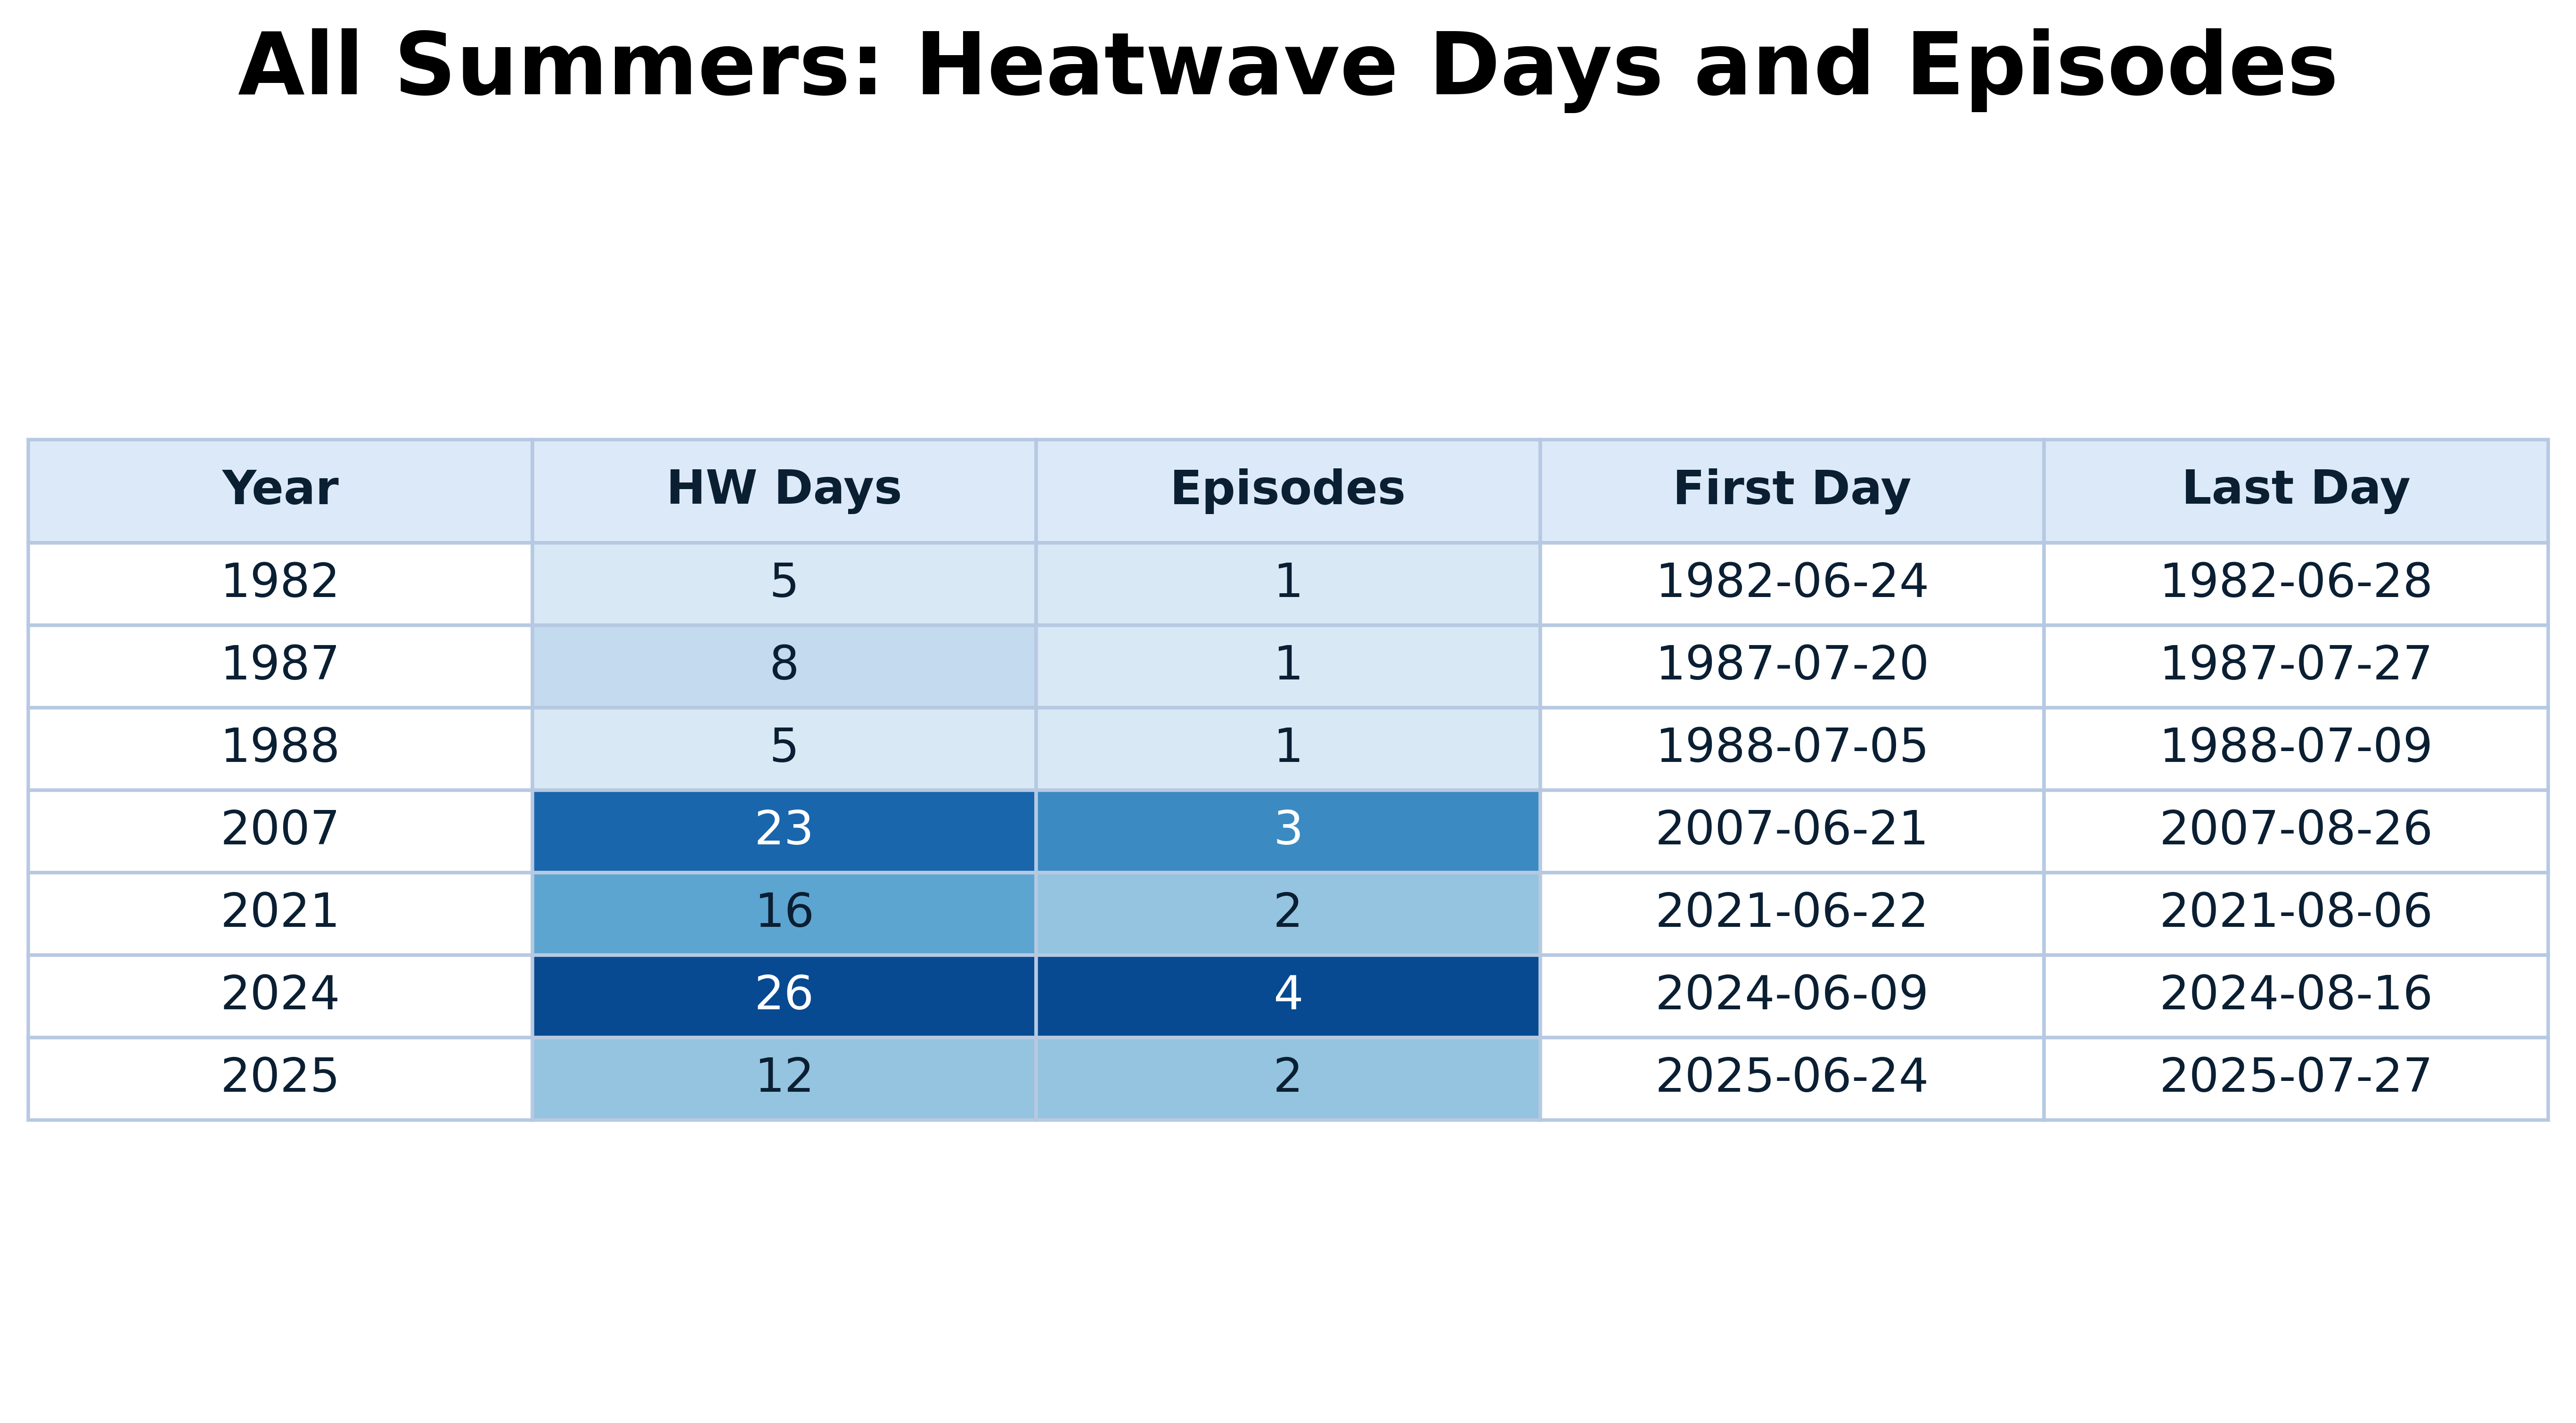

Saved: table1_heatwave_summary_600dpi.png


/tmp/ipykernel_2880668/1566866695.py:154: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Blues")


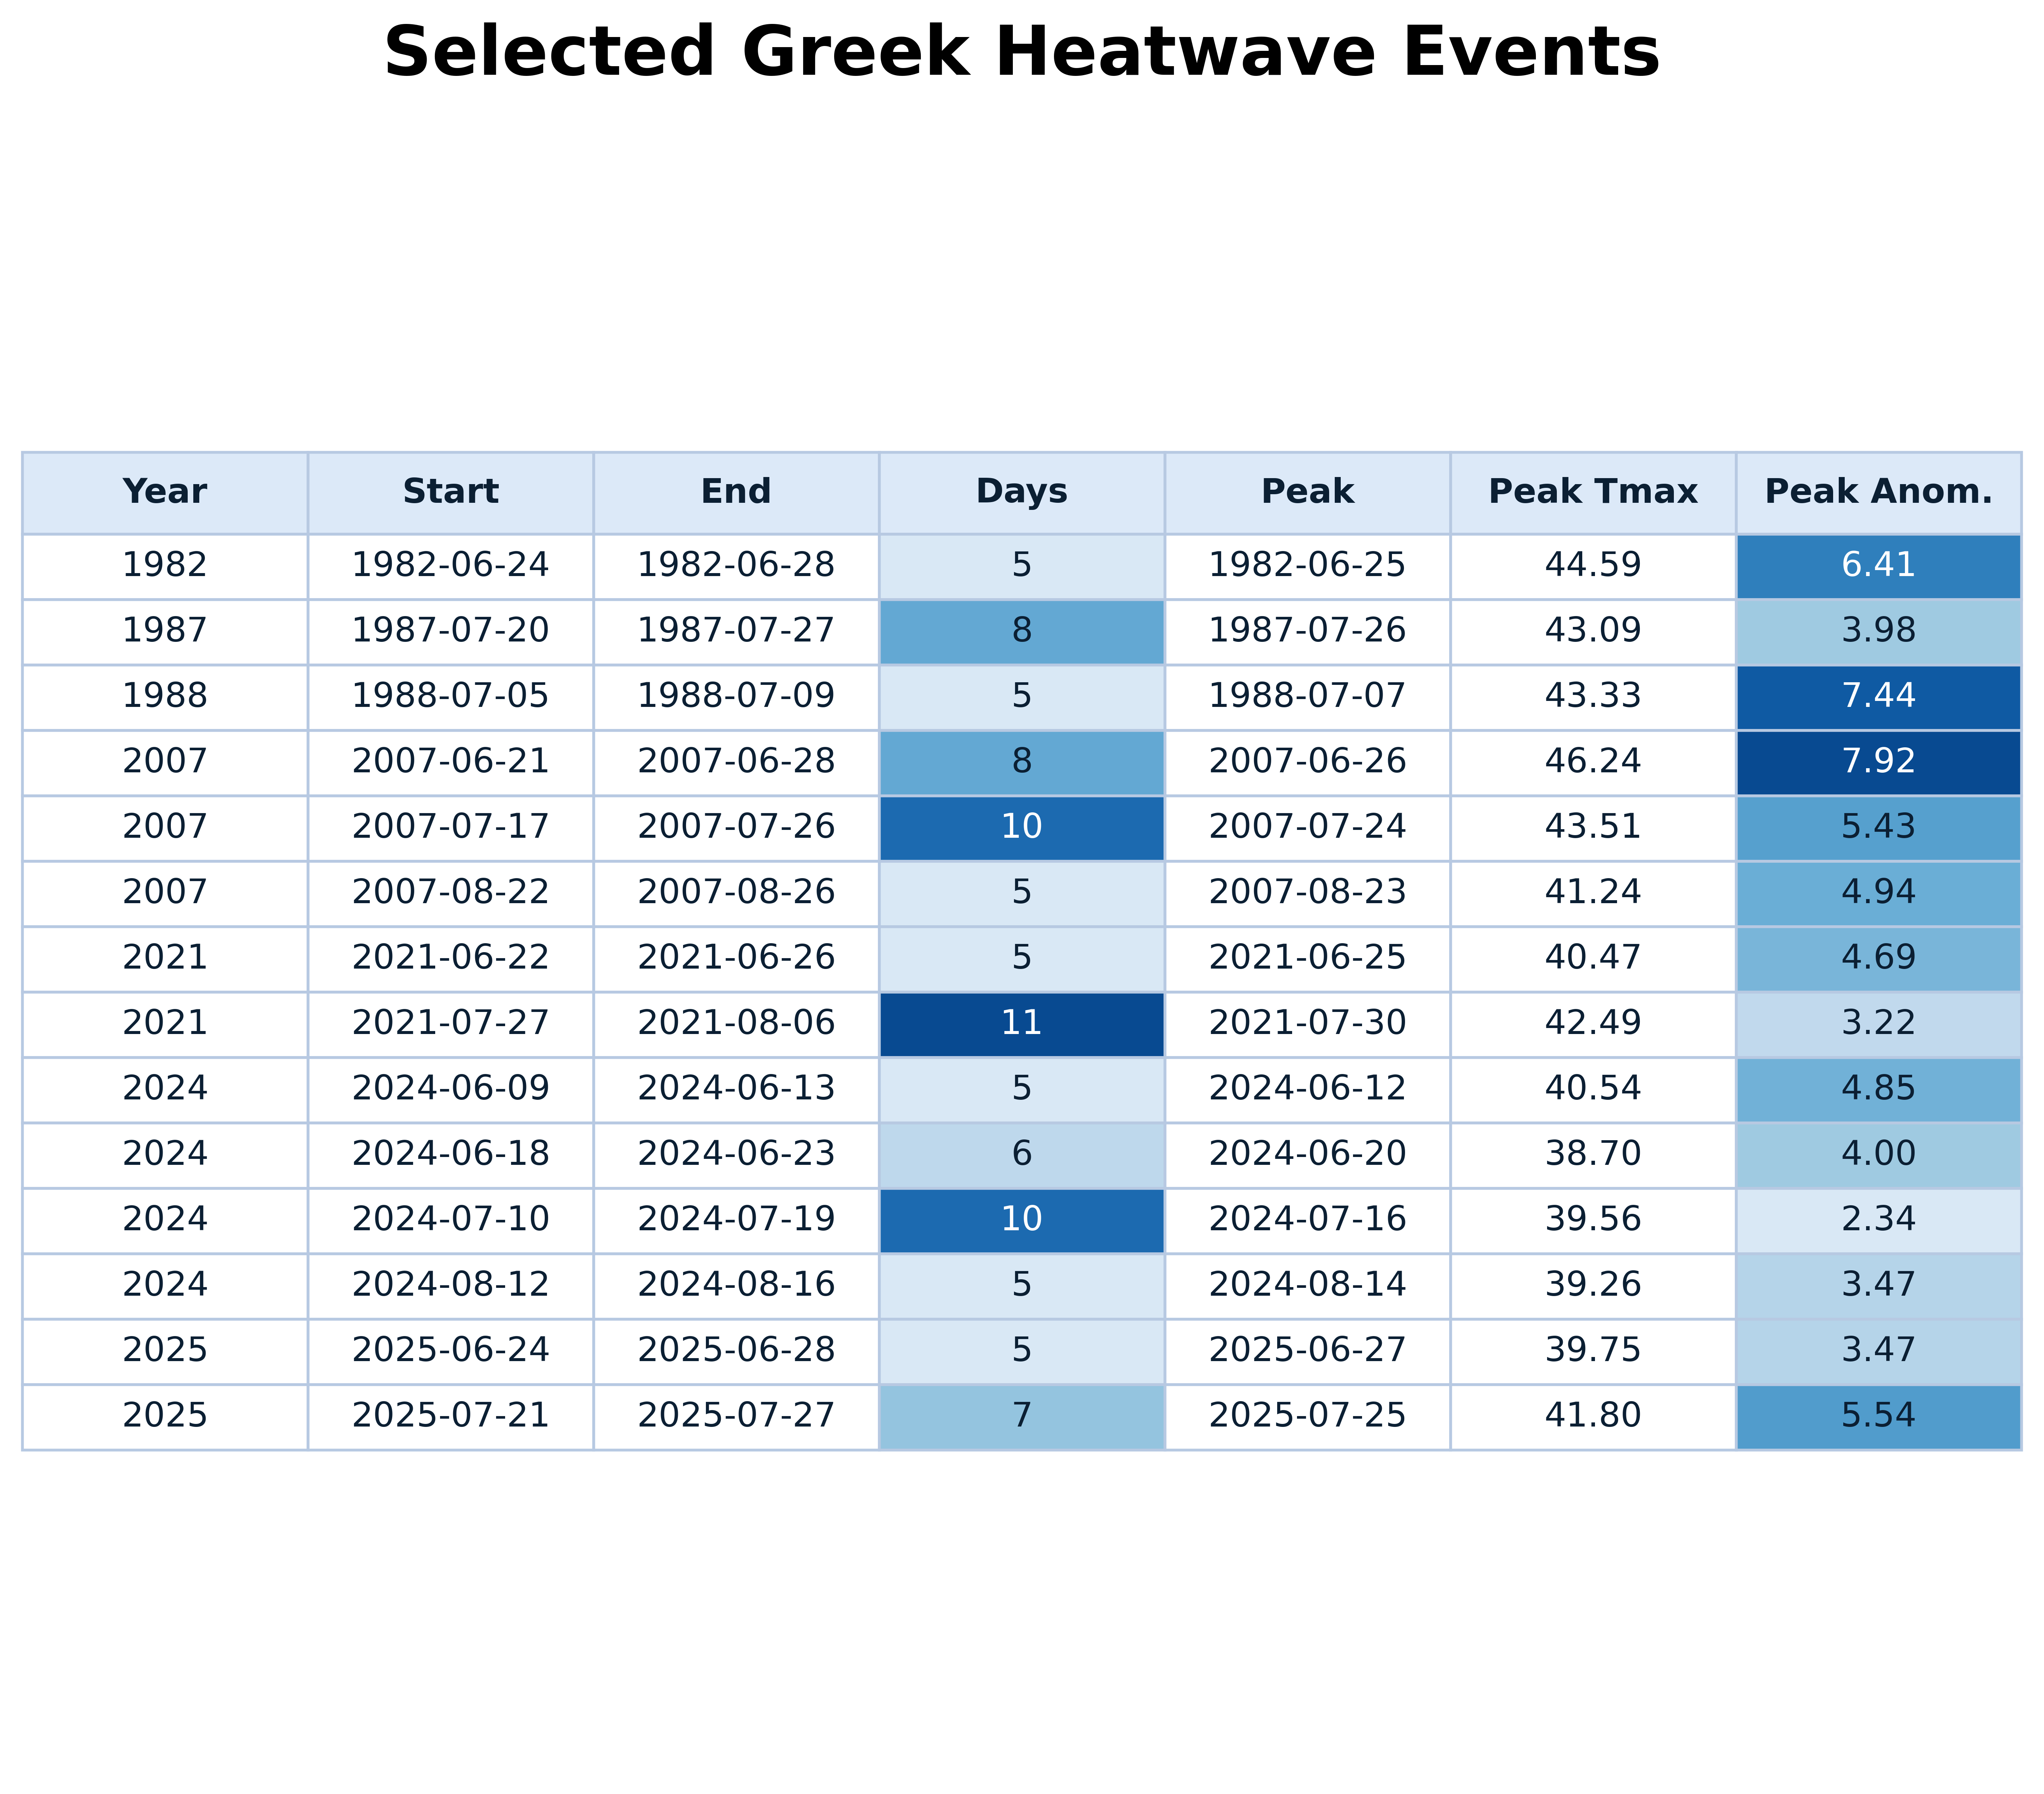

Saved: table2_selected_heatwave_events_600dpi.png


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors

# ============================================================
# 1. INPUT DATAFRAMES
#    Assumes you already have:
#    - year_df
#    - episodes_df
# ============================================================

year_summary = year_df.copy()
event_catalogue = episodes_df.copy()

year_summary["first_heatwave_day"] = pd.to_datetime(year_summary["first_heatwave_day"])
year_summary["last_heatwave_day"] = pd.to_datetime(year_summary["last_heatwave_day"])

event_catalogue["start_date"] = pd.to_datetime(event_catalogue["start_date"])
event_catalogue["end_date"] = pd.to_datetime(event_catalogue["end_date"])
event_catalogue["peak_day"] = pd.to_datetime(event_catalogue["peak_day"])

if "year" not in event_catalogue.columns:
    event_catalogue["year"] = event_catalogue["start_date"].dt.year

# ============================================================
# 2. SELECT YEARS FOR TABLE 2
# ============================================================

years_keep = [1987, 2007, 2021, 2023, 2024]

# ============================================================
# 3. TABLE 1: YEAR SUMMARY
# ============================================================

table1 = year_summary.copy().sort_values("year")

table1["first_heatwave_day"] = table1["first_heatwave_day"].dt.strftime("%Y-%m-%d")
table1["last_heatwave_day"] = table1["last_heatwave_day"].dt.strftime("%Y-%m-%d")

table1 = table1[
    [
        "year",
        "n_heatwave_days",
        "n_events_rows",
        "first_heatwave_day",
        "last_heatwave_day",
    ]
].rename(columns={
    "year": "Year",
    "n_heatwave_days": "HW Days",
    "n_events_rows": "Episodes",
    "first_heatwave_day": "First Day",
    "last_heatwave_day": "Last Day",
})

# ============================================================
# 4. TABLE 2: EVENT DETAILS
# ============================================================

table2 = (
    event_catalogue#[event_catalogue["year"].isin(years_keep)]
    .copy()
    .sort_values(["year", "start_date", "end_date"])
)

ANOM_THRESHOLD = 0.0
ANOM_ADD = 0.0

table2["peak_day_max_temp_anom_adjusted"] = table2["peak_day_max_temp_anom"].where(
    table2["peak_day_max_temp_anom"] >= ANOM_THRESHOLD,
    table2["peak_day_max_temp_anom"] + ANOM_ADD
)

table2["start_date"] = table2["start_date"].dt.strftime("%Y-%m-%d")
table2["end_date"] = table2["end_date"].dt.strftime("%Y-%m-%d")
table2["peak_day"] = table2["peak_day"].dt.strftime("%Y-%m-%d")

table2 = table2[
    [
        "year",
        "start_date",
        "end_date",
        "duration_days",
        "peak_day",
        "peak_day_max_temp",
        "peak_day_max_temp_anom_adjusted",
    ]
].rename(columns={
    "year": "Year",
    "start_date": "Start",
    "end_date": "End",
    "duration_days": "Days",
    "peak_day": "Peak",
    "peak_day_max_temp": "Peak Tmax",
    "peak_day_max_temp_anom_adjusted": "Peak Anom.",
})

# ============================================================
# 5. SAVE TABLE AS HIGH-QUALITY PNG USING MATPLOTLIB
# ============================================================

def save_table_matplotlib(
    df,
    filename,
    title,
    gradient_cols=None,
    dpi=600,
    fontsize=12,
    header_fontsize=12,
    title_fontsize=22
):
    if gradient_cols is None:
        gradient_cols = []

    df_plot = df.copy()

    # format values
    for col in df_plot.columns:
        if pd.api.types.is_float_dtype(df_plot[col]):
            df_plot[col] = df_plot[col].map(lambda x: f"{x:.2f}" if pd.notnull(x) else "")
        elif pd.api.types.is_integer_dtype(df_plot[col]):
            df_plot[col] = df_plot[col].map(lambda x: f"{int(x)}" if pd.notnull(x) else "")
        else:
            df_plot[col] = df_plot[col].astype(str)

    nrows, ncols = df_plot.shape

    # wider figure for second table
    fig_width = max(10, ncols * 1.35)
    fig_height = max(3.0, nrows * 0.55 + 1.8)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=dpi)
    ax.axis("off")

    ax.set_title(title, fontsize=title_fontsize, fontweight="bold", pad=18)

    table = ax.table(
        cellText=df_plot.values,
        colLabels=df_plot.columns,
        cellLoc="center",
        colLoc="center",
        loc="center"
    )

    table.auto_set_font_size(False)
    table.set_fontsize(fontsize)
    table.scale(1.15, 1.75)

    # colors
    header_color = "#dce9f8"
    border_color = "#b7c9e2"
    text_color = "#0b1f33"
    cmap = cm.get_cmap("Blues")

    # prepare normalization for gradient columns
    norms = {}
    for col in gradient_cols:
        if col in df.columns:
            vals = pd.to_numeric(df[col], errors="coerce")
            norms[col] = colors.Normalize(vmin=np.nanmin(vals), vmax=np.nanmax(vals))

    # style cells
    for (row, col_idx), cell in table.get_celld().items():
        cell.set_edgecolor(border_color)
        cell.set_linewidth(0.9)

        if row == 0:
            cell.set_facecolor(header_color)
            cell.set_text_props(weight="bold", color=text_color, fontsize=header_fontsize)
            cell.set_height(cell.get_height() * 1.25)

        else:
            col_name = df.columns[col_idx]

            if col_name in gradient_cols:
                value = pd.to_numeric(df.iloc[row - 1, col_idx], errors="coerce")

                if pd.notnull(value):
                    rgba = cmap(0.15 + 0.75 * norms[col_name](value))
                    cell.set_facecolor(rgba)

                    # white text for darkest values
                    if norms[col_name](value) > 0.65:
                        cell.set_text_props(color="white", fontsize=fontsize)
                    else:
                        cell.set_text_props(color=text_color, fontsize=fontsize)
                else:
                    cell.set_facecolor("white")
                    cell.set_text_props(color=text_color, fontsize=fontsize)

            else:
                cell.set_facecolor("white")
                cell.set_text_props(color=text_color, fontsize=fontsize)

    plt.savefig(
        filename,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {filename}")

# ============================================================
# 6. SAVE TABLE 1
# ============================================================

save_table_matplotlib(
    table1,
    filename="table1_heatwave_summary_600dpi.png",
    title="All Summers: Heatwave Days and Episodes",
    gradient_cols=["HW Days", "Episodes"],
    dpi=600,
    fontsize=12,
    header_fontsize=12,
    title_fontsize=22
)

# ============================================================
# 7. SAVE TABLE 2
# ============================================================

save_table_matplotlib(
    table2,
    filename="table2_selected_heatwave_events_600dpi.png",
    title="Selected Greek Heatwave Events",
    gradient_cols=["Days", "Peak Anom."],
    dpi=600,
    fontsize=11,
    header_fontsize=11,
    title_fontsize=22
)

/tmp/ipykernel_2880668/767127871.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap("Blues")


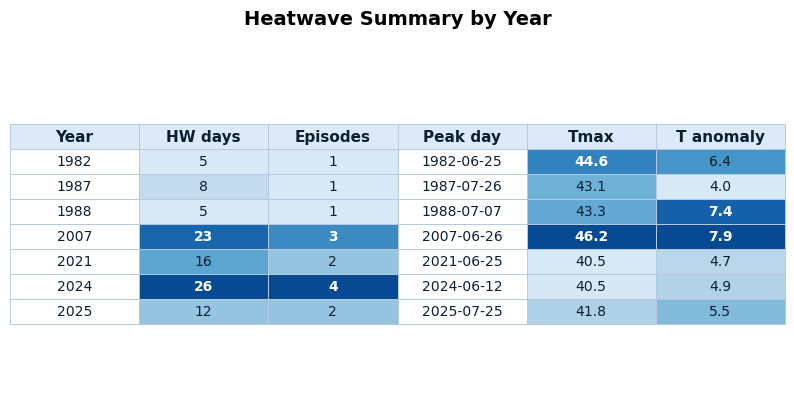

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm, colors

# ============================================================
# 1. PREPARE DATA
# ============================================================

year_summary = year_df.copy()
events = episodes_df.copy()

year_summary["year"] = year_summary["year"].astype(int)
events["peak_day"] = pd.to_datetime(events["peak_day"])

if "year" not in events.columns:
    events["year"] = pd.to_datetime(events["start_date"]).dt.year

# strongest event per year based on temperature anomaly
peak_events = (
    events.sort_values(["year", "peak_day_max_temp_anom"], ascending=[True, False])
          .groupby("year")
          .head(1)
          [["year", "peak_day", "peak_day_max_temp", "peak_day_max_temp_anom"]]
)

# merge yearly summary + peak event info
table1 = year_summary.merge(peak_events, on="year", how="left")

table1 = table1[
    [
        "year",
        "n_heatwave_days",
        "n_events_rows",
        "peak_day",
        "peak_day_max_temp",
        "peak_day_max_temp_anom",
    ]
]

table1 = table1.rename(columns={
    "year": "Year",
    "n_heatwave_days": "HW days",
    "n_events_rows": "Episodes",
    "peak_day": "Peak day",
    "peak_day_max_temp": "Tmax",
    "peak_day_max_temp_anom": "T anomaly",
})

table1 = table1.sort_values("Year").reset_index(drop=True)

# keep numeric copy for gradient shading
table1_numeric = table1.copy()

# formatting for display
table1["Peak day"] = pd.to_datetime(table1["Peak day"]).dt.strftime("%Y-%m-%d")
table1["Tmax"] = table1["Tmax"].map(lambda x: f"{x:.1f}" if pd.notnull(x) else "")
table1["T anomaly"] = table1["T anomaly"].map(lambda x: f"{x:.1f}" if pd.notnull(x) else "")

# ============================================================
# 2. MAKE CLEAN TABLE FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(10, 0.45 * len(table1) + 1.5))
ax.axis("off")

tbl = ax.table(
    cellText=table1.values,
    colLabels=table1.columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[1 / 6] * 6
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1.0, 1.5)

# ============================================================
# 3. BLUE GRADIENT SHADING
# ============================================================

gradient_cols = ["HW days", "Episodes", "Tmax", "T anomaly"]

cmap = cm.get_cmap("Blues")
norms = {}

for col in gradient_cols:
    vals = pd.to_numeric(table1_numeric[col], errors="coerce")
    norms[col] = colors.Normalize(vmin=vals.min(), vmax=vals.max())

for (row, col), cell in tbl.get_celld().items():

    cell.set_edgecolor("#b7c9e2")
    cell.set_linewidth(0.7)

    if row == 0:
        cell.set_facecolor("#dce9f8")
        cell.set_text_props(weight="bold", fontsize=11, color="#0b1f33")

    else:
        col_name = table1.columns[col]

        if col_name in gradient_cols:
            value = pd.to_numeric(table1_numeric.iloc[row - 1, col], errors="coerce")

            if pd.notnull(value):
                strength = norms[col_name](value)
                cell.set_facecolor(cmap(0.15 + 0.75 * strength))

                if strength > 0.65:
                    cell.set_text_props(fontsize=10, color="white", weight="bold")
                else:
                    cell.set_text_props(fontsize=10, color="#0b1f33")
            else:
                cell.set_facecolor("white")
                cell.set_text_props(fontsize=10, color="#0b1f33")

        else:
            cell.set_facecolor("white")
            cell.set_text_props(fontsize=10, color="#0b1f33")

plt.title("Heatwave Summary by Year", fontsize=14, weight="bold", pad=15)

plt.savefig(
    "table1_heatwave_summary_blue_gradient.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

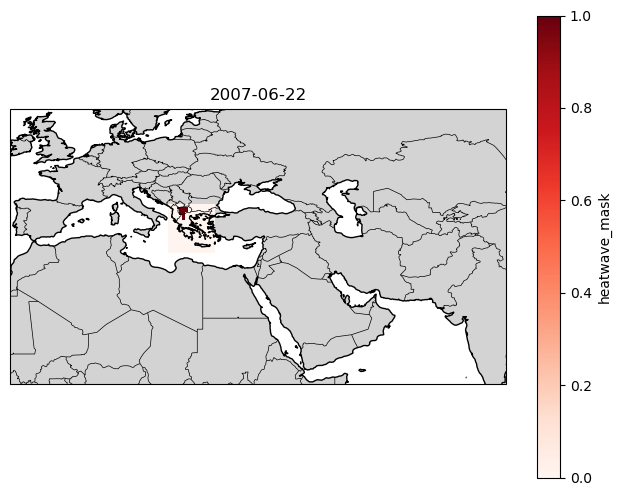

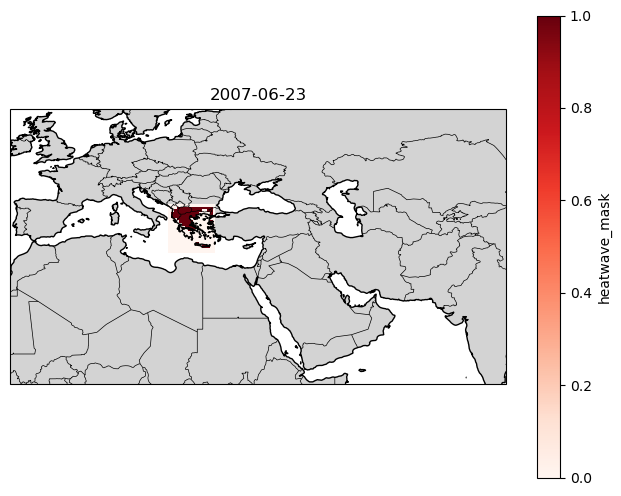

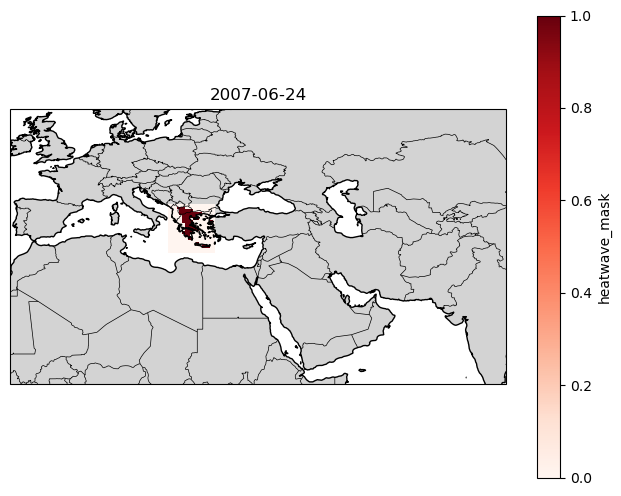

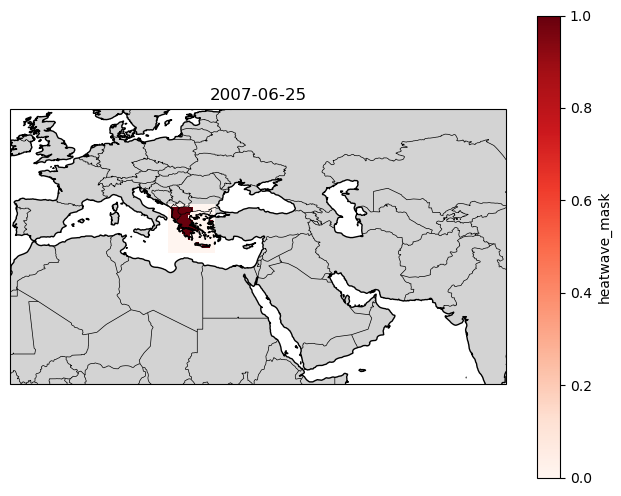

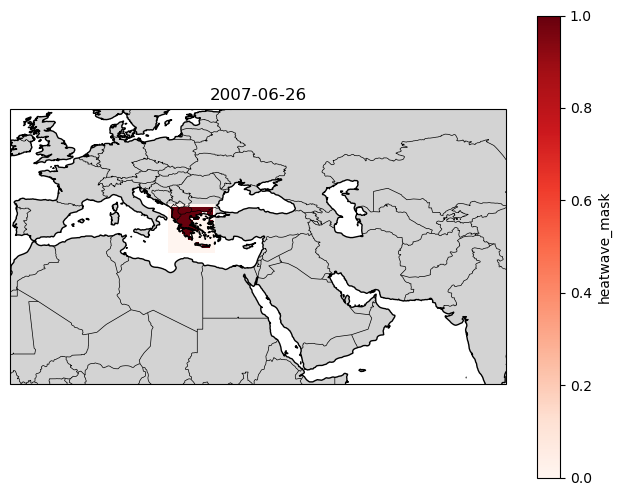

In [18]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

for i in range(5):
    da = final_mask.sel(time=slice('2007-06-22','2007-06-27'))[i,:,:]

    fig = plt.figure(figsize=(8, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

   
    ax.set_extent([-10, 80, 10, 60], crs=ccrs.PlateCarree())

   
    ax.coastlines(resolution='50m')
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='white')

    
    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='Reds',
        
        add_colorbar=True
    )

    ax.set_title(str(da.time.values)[:10])
    plt.show()

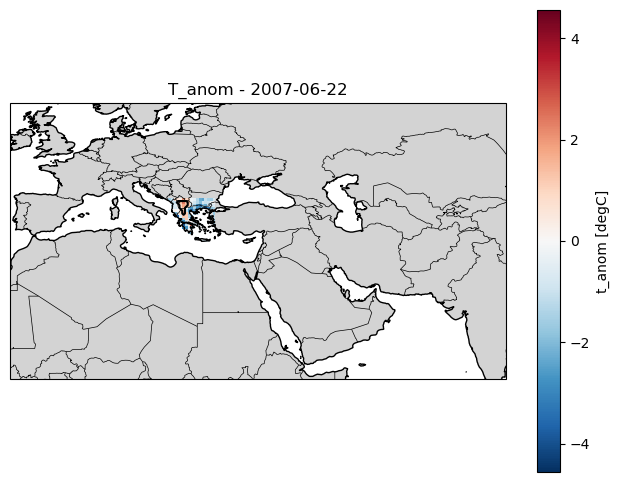

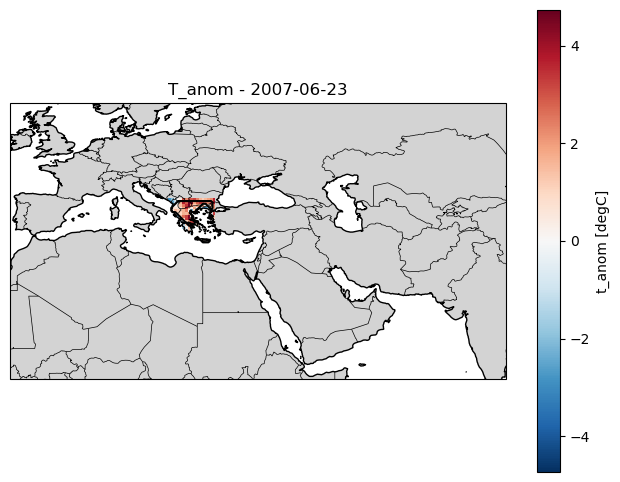

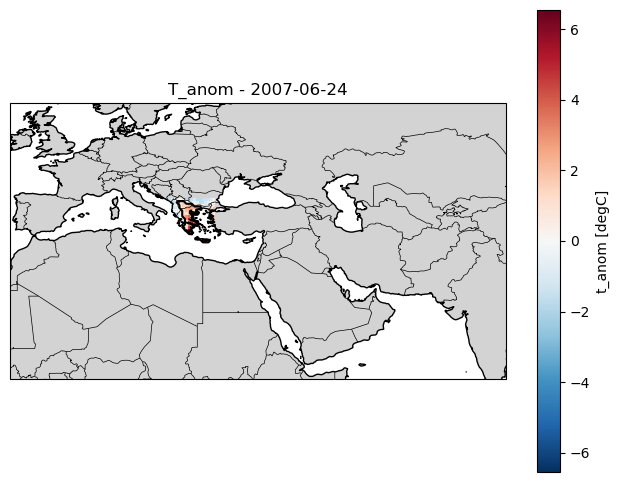

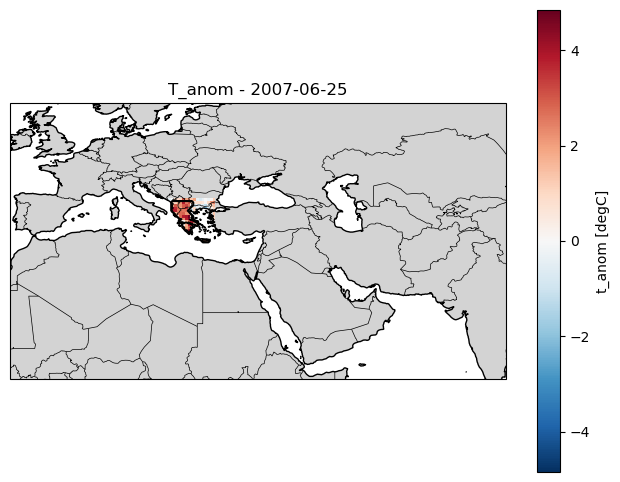

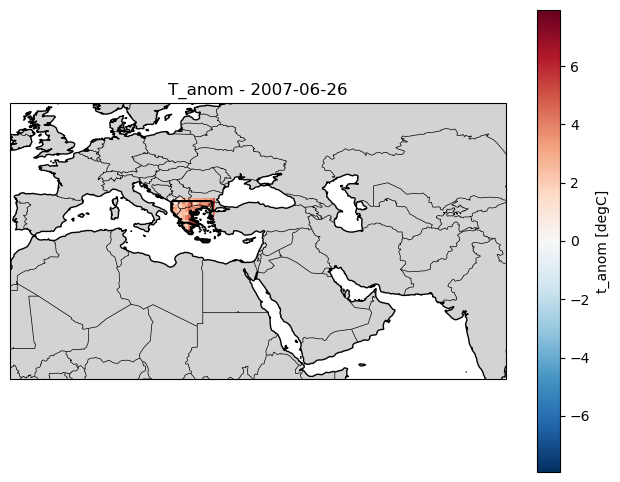

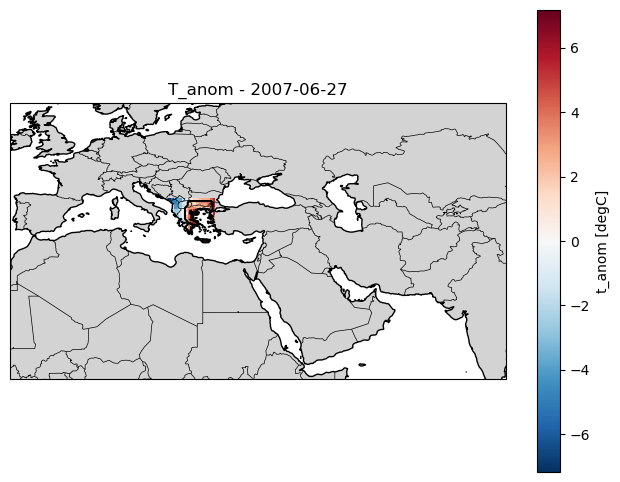

In [19]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

plot_data = t_anom.sel(time=slice('2007-06-22','2007-06-27'))
mask_data = final_mask.sel(time=slice('2007-06-22','2007-06-27'))
for i in range(plot_data.time.size):
    da = plot_data.isel(time=i)
    mask = mask_data.isel(time=i)

    fig = plt.figure(figsize=(8, 6))
    ax = plt.axes(projection=ccrs.PlateCarree())

    ax.set_extent([-10, 80, 10, 60], crs=ccrs.PlateCarree())
    ax.coastlines(resolution='50m')
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.OCEAN, facecolor='white')

    da.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',
        add_colorbar=True
    )

    mask.plot.contour(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=[0.5],
        colors='black',
        linewidths=1.5,
        add_colorbar=False
    )

    ax.set_title(f"T_anom - {str(da.time.values)[:10]}")
    plt.show()

In [38]:
########################## T_NAOM>0 @@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

# ============================================================
# SETTINGS
# ============================================================
input_file = "/jetfs/scratch/vdeshmukh/2m_data_temp/ERA5_t2m_1979_2025_0p5_land_MJJA.nc"
output_file = "part_ic.nc"

start_date = "2021-06-20 06:00:00"
end_date   = "2021-08-10 18:00:00"
lat_range = slice(34.0, 42.5)
lon_range = slice(19.0, 27.0)



keep_hours = [6, 9, 12, 15, 18]

particle_per_grid = 300
height_m = 50.0

species_ids = np.array([24], dtype=np.int64)
kindz = np.int64(1)

# ============================================================
# OPEN SUBDAILY DATA
# ============================================================
ds = xr.open_dataset(input_file)

ds_sel = ds.sel(
    lat=lat_range,
    lon=lon_range,
    time=slice(start_date, end_date)
)

ds_sel = ds_sel.sel(time=ds_sel.time.dt.hour.isin(keep_hours))

if ds_sel.time.size == 0:
    raise ValueError("No time steps found in selected period.")

# ============================================================
# DAILY t_anom ON EXACT SAME GRID AS ds_sel
# t_anom must already exist in memory
# ============================================================
anom_daily = t_anom.sel(
    time=slice(start_date[:10], end_date[:10])
).reindex(
    lat=ds_sel.lat,
    lon=ds_sel.lon,
    method="nearest"
)

if anom_daily.time.size == 0:
    raise ValueError("No daily t_anom found in selected period.")

# ============================================================
# PREPARE GRID
# ============================================================
lon2d, lat2d = np.meshgrid(ds_sel.lon.values, ds_sel.lat.values)

all_lon = []
all_lat = []
all_height = []
all_time = []
all_release = []

run_reference = np.datetime64(end_date)
release_counter = 1

# ============================================================
# LOOP OVER EACH SELECTED SUBDAILY TIME
# ============================================================
for tt in ds_sel.time.values:
    tt = np.datetime64(tt)
    day_str = pd.to_datetime(tt).strftime("%Y-%m-%d")

    day_anom = anom_daily.sel(time=day_str)

    # positive daily anomaly cells only
    release_mask = day_anom.values > -2  

    if not np.any(release_mask):
        release_counter += 1
        continue

    rel_lon = lon2d[release_mask]
    rel_lat = lat2d[release_mask]

    rel_time_sec = int((tt - run_reference) / np.timedelta64(1, "s"))
    rel_lon = np.repeat(rel_lon, particle_per_grid).astype(np.float64)
    rel_lat = np.repeat(rel_lat, particle_per_grid).astype(np.float64)
    rel_height = np.full(rel_lon.size, height_m, dtype=np.float64) 
    #rel_height = np.random.uniform(low=0.0, high=height_m, size=rel_lon.size).astype(np.float64) # to uniformly distribute particles in height
    rel_time = np.full(rel_lon.size, rel_time_sec, dtype=np.int64)
    rel_release = np.full(rel_lon.size, release_counter, dtype=np.int64)

    all_lon.append(rel_lon)
    all_lat.append(rel_lat)
    all_height.append(rel_height)
    all_time.append(rel_time)
    all_release.append(rel_release)

    release_counter += 1

# ============================================================
# CHECK OUTPUT
# ============================================================
if len(all_lon) == 0:
    raise ValueError("No release points found with t_anom > 0 in the selected period.")

part_lon = np.concatenate(all_lon)
part_lat = np.concatenate(all_lat)
part_height = np.concatenate(all_height)
part_time = np.concatenate(all_time)
part_release = np.concatenate(all_release)

num_part = len(part_lon)
nspecies = len(species_ids)

part_mass = np.ones((nspecies, num_part), dtype=np.float64)

# ============================================================
# WRITE FILE
# ============================================================
ds_out = xr.Dataset(
    data_vars={
        "longitude": (["particle"], part_lon),
        "latitude":  (["particle"], part_lat),
        "height":    (["particle"], part_height),
        "time":      (["particle"], part_time),
        "mass":      (["species", "particle"], part_mass),
        "release":   (["particle"], part_release),
    },
    coords={
        "particle": np.arange(num_part, dtype=np.int64),
        "species": np.arange(nspecies, dtype=np.int64),
    }
)

ds_out.attrs["nspecies"] = np.int64(nspecies)
ds_out.attrs["species"] = species_ids
ds_out.attrs["kindz"] = kindz

ds_out.to_netcdf(output_file)

ds_out.close()
ds.close()

print("Saved:", output_file)
print("Number of releases:", len(np.unique(part_release)))
print("Total particles:", num_part)
print("Unique time values:", np.unique(part_time),len(np.unique(part_time)))

Saved: part_ic.nc
Number of releases: 260
Total particles: 4873500
Unique time values: [-4449600 -4438800 -4428000 -4417200 -4406400 -4363200 -4352400 -4341600
 -4330800 -4320000 -4276800 -4266000 -4255200 -4244400 -4233600 -4190400
 -4179600 -4168800 -4158000 -4147200 -4104000 -4093200 -4082400 -4071600
 -4060800 -4017600 -4006800 -3996000 -3985200 -3974400 -3931200 -3920400
 -3909600 -3898800 -3888000 -3844800 -3834000 -3823200 -3812400 -3801600
 -3758400 -3747600 -3736800 -3726000 -3715200 -3672000 -3661200 -3650400
 -3639600 -3628800 -3585600 -3574800 -3564000 -3553200 -3542400 -3499200
 -3488400 -3477600 -3466800 -3456000 -3412800 -3402000 -3391200 -3380400
 -3369600 -3326400 -3315600 -3304800 -3294000 -3283200 -3240000 -3229200
 -3218400 -3207600 -3196800 -3153600 -3142800 -3132000 -3121200 -3110400
 -3067200 -3056400 -3045600 -3034800 -3024000 -2980800 -2970000 -2959200
 -2948400 -2937600 -2894400 -2883600 -2872800 -2862000 -2851200 -2808000
 -2797200 -2786400 -2775600 -2764800 

In [32]:
#########################################
#part_ic_end_start_land_masked simpleeeeeeeeeeeeeeeeeeeeee
####################################################



# ============================================================
# SETTINGS- simple release in the box with lan mask 
# ============================================================
input_file = "/jetfs/scratch/vdeshmukh/2m_data_temp/ERA5_t2m_1979_2025_0p5_land_MJJA.nc"
output_file = "part_ic_2025.nc"

start_date = "2025-06-01 06:00:00"
end_date   = "2025-07-31 18:00:00"

lat_range = slice(34, 42.5)
lon_range = slice(19, 27)

keep_hours = [6, 9, 12, 15, 18]

particle_per_grid = 300
height_m = 50.0

species_ids = np.array([24], dtype=np.int64)
kindz = np.int64(1)

# ============================================================
# OPEN + SELECT
# ============================================================
ds = xr.open_dataset(input_file)

ds_sel = ds.sel(
    lat=lat_range,
    lon=lon_range,
    time=slice(start_date, end_date)
)

ds_sel = ds_sel.sel(time=ds_sel.time.dt.hour.isin(keep_hours))

if ds_sel.time.size == 0:
    raise ValueError("No time steps found in selected period.")

# ============================================================
# LAND MASK
# ============================================================
first_var = list(ds_sel.data_vars)[0]
land_mask = ds_sel[first_var].isel(time=0).notnull()

lon2d, lat2d = np.meshgrid(ds_sel.lon.values, ds_sel.lat.values)
mask = land_mask.values

land_lon = lon2d[mask]
land_lat = lat2d[mask]

if land_lon.size == 0:
    raise ValueError("No land points found in selected box.")

# ============================================================
# BACKWARD TIME: 0 at end_date, earlier times negative
# ============================================================
time_values = ds_sel.time.values
run_reference = np.datetime64(end_date)
times_sec = ((time_values - run_reference) / np.timedelta64(1, "s")).astype(np.int64)

nland = len(land_lon)
ntimes = len(times_sec)

# ============================================================
# BUILD PARTICLES
# ============================================================
part_lon = np.tile(land_lon, ntimes)
part_lat = np.tile(land_lat, ntimes)
part_height = np.full(ntimes * nland, height_m, dtype=np.float64)

part_time = np.repeat(times_sec, nland).astype(np.int64)

# release number per timestep
part_release = np.repeat(np.arange(1, ntimes + 1, dtype=np.int64), nland)

# repeat each grid-cell release particle_per_grid times
part_lon = np.repeat(part_lon, particle_per_grid).astype(np.float64)
part_lat = np.repeat(part_lat, particle_per_grid).astype(np.float64)
part_height = np.repeat(part_height, particle_per_grid).astype(np.float64)
part_time = np.repeat(part_time, particle_per_grid).astype(np.int64)
part_release = np.repeat(part_release, particle_per_grid).astype(np.int64)

num_part = len(part_lon)
nspecies = len(species_ids)

part_mass = np.ones((nspecies, num_part), dtype=np.float64)

# ============================================================
# OUTPUT DATASET
# ============================================================
ds_out = xr.Dataset(
    data_vars={
        "longitude": (["particle"], part_lon),
        "latitude":  (["particle"], part_lat),
        "height":    (["particle"], part_height),
        "time":      (["particle"], part_time),
        "mass":      (["species", "particle"], part_mass),
        "release":   (["particle"], part_release),
    },
    coords={
        "particle": np.arange(num_part, dtype=np.int64),
        "species": np.arange(nspecies, dtype=np.int64),
    }
)

ds_out.attrs["nspecies"] = np.int64(nspecies)
ds_out.attrs["species"] = species_ids
ds_out.attrs["kindz"] = kindz

ds_out.to_netcdf(output_file)

release_times = pd.to_datetime(ds_sel.time.values)

ds_out.close()
ds.close()

print("Saved:", output_file)
print("Number of land points:", nland)
print("Number of times:", ntimes)
print("Total particles:", num_part)
print("First release time:", release_times.min())
print("Last release time :", release_times.max())
print("Unique time values:", np.unique(part_time)[:10], "...")

Saved: part_ic_2025.nc
Number of land points: 124
Number of times: 305
Total particles: 11346000
First release time: 2025-06-01 06:00:00
Last release time : 2025-07-31 18:00:00
Unique time values: [-5227200 -5216400 -5205600 -5194800 -5184000 -5140800 -5130000 -5119200
 -5108400 -5097600] ...


In [30]:
ds = xr.open_dataset(input_file)

# Select only 2025
ds_2025 = ds.sel(time=slice("2025-01-01", "2025-12-31"))

# Number of months represented in 2025
ds_2025.sel(time='2025-06-01')

<xarray.Dataset> Size: 8MB
Dimensions:  (time: 8, lon: 720, lat: 361)
Coordinates:
  * time     (time) datetime64[ns] 64B 2025-06-01 ... 2025-06-01T21:00:00
  * lon      (lon) float64 6kB 0.0 0.5 1.0 1.5 2.0 ... 358.0 358.5 359.0 359.5
  * lat      (lat) float64 3kB -90.0 -89.5 -89.0 -88.5 ... 88.5 89.0 89.5 90.0
Data variables:
    2t       (time, lat, lon) float32 8MB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.4 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    institution:  European Centre for Medium-Range Weather Forecasts
    history:      Mon Jul 13 14:34:13 2026: cdo mul landmask.nc renamed_augus...
    CDO:          Climate Data Operators version 2.4.4 (https://mpimet.mpg.de...

In [41]:
import xarray as xr
import pandas as pd

ds = xr.open_dataset("/jetfs/scratch/vdeshmukh/2m_data_temp/ERA5_t2m_1979_2025_0p5_land_MJJA.nc")
t = pd.to_datetime(ds.time.values)

MONTHS = [5, 6, 7, 8]          # MJJA; use [6, 7, 8] for JJA only

bad = False
for year in sorted(set(t.year)):
    for month in MONTHS:
        expected = pd.Period(f"{year}-{month:02d}").days_in_month
        found = len(set(t[(t.year == year) & (t.month == month)].day))
        if found < expected:
            print(f"{year}-{month:02d}: {found}/{expected} days")
            bad = True

if not bad:
    print("All years have complete months.")

2025-08: 0/31 days


In [25]:
part_ic = xr.open_dataset('/jetfs/scratch/vdeshmukh/2007_grecce_heatwave2/options/part_ic.nc')
import numpy as np
import pandas as pd
import xarray as xr

f = "/jetfs/scratch/vdeshmukh/2007_grecce_heatwave2/options/part_ic.nc"
END = "2007-08-31 18:00:00"          # = end_date used to make this file

part_ic = xr.open_dataset(f)
t_sec = part_ic["time"].values
rel = part_ic["release"].values

# one time per release
sec_unique, idx = np.unique(t_sec, return_index=True)
times = pd.Timestamp(END) + pd.to_timedelta(sec_unique, unit="s")

print("Number of release times:", len(times))
print("First:", times.min(), "  Last:", times.max())
print("Particles per release:", np.bincount(rel)[1:].min(), "to", np.bincount(rel)[1:].max())
print("\nReleases per month:")
print(pd.Series(times).dt.month.value_counts().sort_index())
print("\nHours used:", sorted(set(times.hour)))
print("\nAll release times:")
print(times.strftime("%Y-%m-%d %H:%M").tolist())

Number of release times: 460
First: 2007-06-01 06:00:00   Last: 2007-08-31 18:00:00
Particles per release: 37200 to 37200

Releases per month:
6    150
7    155
8    155
Name: count, dtype: int64

Hours used: [6, 9, 12, 15, 18]

All release times:
['2007-06-01 06:00', '2007-06-01 09:00', '2007-06-01 12:00', '2007-06-01 15:00', '2007-06-01 18:00', '2007-06-02 06:00', '2007-06-02 09:00', '2007-06-02 12:00', '2007-06-02 15:00', '2007-06-02 18:00', '2007-06-03 06:00', '2007-06-03 09:00', '2007-06-03 12:00', '2007-06-03 15:00', '2007-06-03 18:00', '2007-06-04 06:00', '2007-06-04 09:00', '2007-06-04 12:00', '2007-06-04 15:00', '2007-06-04 18:00', '2007-06-05 06:00', '2007-06-05 09:00', '2007-06-05 12:00', '2007-06-05 15:00', '2007-06-05 18:00', '2007-06-06 06:00', '2007-06-06 09:00', '2007-06-06 12:00', '2007-06-06 15:00', '2007-06-06 18:00', '2007-06-07 06:00', '2007-06-07 09:00', '2007-06-07 12:00', '2007-06-07 15:00', '2007-06-07 18:00', '2007-06-08 06:00', '2007-06-08 09:00', '2007-06-08

In [15]:
part_ic.height

<xarray.DataArray 'height' (particle: 889500)> Size: 7MB
[889500 values with dtype=float64]
Coordinates:
  * particle  (particle) int64 7MB 0 1 2 3 4 ... 889496 889497 889498 889499

In [16]:
import numpy as np

unique_heights = np.unique(part_ic.height.values)

len(unique_heights)

1

In [17]:
unique_heights, counts = np.unique(part_ic.height.values, return_counts=True)

for h, n in zip(unique_heights, counts):
    print(f"{h:.2f} m: {n} particles")

100.00 m: 889500 particles


In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# choose one 2012 event
start_date = "2012-07-11"
end_date   = "2012-07-17"

# mean anomaly and mean mask over the event
da_mean = t_anom.sel(time=slice(start_date, end_date)).mean(dim="time")
mask_mean = final_mask.sel(time=slice(start_date, end_date)).mean(dim="time")

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent([18, 31, 33, 43], crs=ccrs.PlateCarree())
ax.coastlines(resolution='50m')
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='white')

da_mean.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='Reds',
    add_colorbar=True
)

mask_mean.plot.contour(
    ax=ax,
    transform=ccrs.PlateCarree(),
    levels=[0.5],
    colors='black',
    linewidths=1.5,
    add_colorbar=False
)

ax.set_title(f"max Tmax anomaly during heatwave\n{start_date} to {end_date}")
plt.show()

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd



TEMP_VAR = "theta_e"      # or "t2m" depending on your file
EVENT_ID = 345       # example event
POINT_LON = 15.0
POINT_LAT = 49.0

# offsets in number of timesteps around the daily maximum
OFFSETS = [-1, 0, 1]

In [ ]:
# ============================================================
#  PREPARE TEMPERATURE
# ============================================================

t = ds_small[TEMP_VAR].copy()
t = t.sortby("time")

# Optional: inspect timestep
dt = pd.to_timedelta((t.time.values[1] - t.time.values[0]))
print("Input timestep:", dt)

In [ ]:
# ============================================================
#  GET EVENT DATES
# ============================================================

ev = events_df.loc[24]

start_date = pd.Timestamp(ev["start_date"])
end_date   = pd.Timestamp(ev["end_date"])

print(ev)
print("Event window:", start_date, "to", end_date)

In [ ]:

import pandas as pd

# --------------------------------------------------
# USER SETTINGS
# --------------------------------------------------
LAT1 = 46.5
LAT2 = 51.5
LON1 = 11.0
LON2 = 19.0

Z1 = 50
Z2 = 50
ZKIND = 1

MASS = 5.09256513e18
PARTS = 50000

NSPEC = 1
SPECNUM_REL = 24

OUTPUT_FILE = "RELEASES"
# --------------------------------------------------

with open(OUTPUT_FILE, "w") as f:
    f.write("&RELEASES_CTRL\n")
    f.write(f" NSPEC       = {NSPEC},\n")
    f.write(f" SPECNUM_REL = {SPECNUM_REL},\n")
    f.write(" /\n")

    for i, row in enumerate(window_df.itertuples(index=False), start=1):
        t = pd.Timestamp(row.sample_time)

        idate = t.strftime("%Y%m%d")
        itime = t.strftime("%H%M%S")

        comment = (
            f"RELEASE {i} "
            f"(event {row.event_id}, peak {pd.Timestamp(row.peak_time).strftime('%Y-%m-%d %H:%M')}, "
            f"offset {row.offset_hour:+d}h)"
        )

        f.write("\n&RELEASE\n")
        f.write(f" IDATE1  = {idate},\n")
        f.write(f" ITIME1  = {itime},\n")
        f.write(f" IDATE2  = {idate},\n")
        f.write(f" ITIME2  = {itime},\n")
        f.write(f" LON1    = {LON1},\n")
        f.write(f" LON2    = {LON2},\n")
        f.write(f" LAT1    = {LAT1},\n")
        f.write(f" LAT2    = {LAT2},\n")
        f.write(f" Z1      = {Z1},\n")
        f.write(f" Z2      = {Z2},\n")
        f.write(f" ZKIND   = {ZKIND},\n")
        f.write(f" MASS    = {MASS:.8E},\n")
        f.write(f" PARTS   = {PARTS},\n")
        f.write(f' COMMENT = "{comment}",\n')
        f.write(" /\n")

print(f"Done. Wrote {OUTPUT_FILE} with {len(window_df)} releases.")

In [ ]:
import numpy as np
import pandas as pd

RUN_START = pd.Timestamp("2024-07-08 00:00:00")  
HEIGHT_METERS = 50.0
RELEASE_BASE = 1

particle_rows = []

for i, row in window_df.iterrows():
    day = pd.Timestamp(row["event_day"])
    sample_time = pd.Timestamp(row["sample_time"])

    # daily heatwave mask for that day
    mask_day = final_mask.sel(time=day)
    mask_np = mask_day.values.astype(bool)

    # indices of masked grid points
    lat_idx, lon_idx = np.where(mask_np)

    if len(lat_idx) == 0:
        print(f"No masked points on {day.date()}")
        continue

    lats = mask_day.lat.values[lat_idx]
    lons = mask_day.lon.values[lon_idx]

    # one release id for each sample_time
    release_id = RELEASE_BASE + i

    for lat_val, lon_val in zip(lats, lons):
        particle_rows.append({
            "sample_time": sample_time,
            "event_day": day,
            "release": release_id,
            "latitude": float(lat_val),
            "longitude": float(lon_val),
            "height": float(HEIGHT_METERS)
        })

# make dataframe
particles_df = pd.DataFrame(particle_rows)

# backward run: time relative to final sample time
RUN_END = pd.Timestamp("2024-07-19 16:00:00")

particles_df["time"] = (
    pd.to_datetime(particles_df["sample_time"]) - RUN_END
).dt.total_seconds().astype("int64")

# ------------------------------------------------------------
# IMPORTANT: sort so latest sample_time comes first
# ------------------------------------------------------------
particles_df = particles_df.sort_values(
    ["sample_time", "release", "latitude", "longitude"],
    ascending=[False, False, True, True]
).reset_index(drop=True)

check_df = particles_df[["sample_time", "time"]].drop_duplicates()
print(check_df.head())
print(check_df.tail())

In [ ]:
particles_df.loc[0]

In [ ]:

particle_per_grid = 10
species_ids = np.array([24], dtype=np.int64)
nspecies = len(species_ids)

# ============================================================
# REPEAT EACH GRID POINT 10 TIMES
# ============================================================

all_lon = []
all_lat = []
all_height = []
all_time = []
all_release = []

for _, row in particles_df.iterrows():
    for _ in range(particle_per_grid):
        all_lon.append(row["longitude"])
        all_lat.append(row["latitude"])
        all_height.append(row["height"])
        all_time.append(row["time"])
        all_release.append(row["release"])


part_lon = np.array(all_lon, dtype=np.float64)
part_lat = np.array(all_lat, dtype=np.float64)
part_height = np.array(all_height, dtype=np.float64)
part_time = np.array(all_time, dtype=np.int64)
part_release = np.array(all_release, dtype=np.int64)

num_part = len(part_lon)

print("no.of particle", num_part)


part_mass = np.ones((nspecies, num_part), dtype=np.float64)
#making dataset 
ds_out = xr.Dataset(
    data_vars={
        "longitude": (["particle"], part_lon),
        "latitude":  (["particle"], part_lat),
        "height":    (["particle"], part_height),
        "time":      (["particle"], part_time),
        "mass":      (["species", "particle"], part_mass),
        "release":   (["particle"], part_release),
    },
    coords={
        "particle": np.arange(num_part, dtype=np.int64),
        "species": np.arange(nspecies, dtype=np.int64),
    }
)

ds_out.attrs["nspecies"] = np.int64(nspecies)
ds_out.attrs["species"] = species_ids
ds_out.attrs["kindz"] = np.int64(2)



ds_out.to_netcdf("part_ic.nc")
ds_out.close()

